# HW2 - SVM
Daniil Miloserdov, Nandana Dileep

run all cells in order. figures are saved into figures/ (we use them in the report), numbers go to results.json

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, time, os
from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Perceptron
from sklearn.svm import LinearSVC, SVC
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

os.makedirs('figures', exist_ok=True)
os.makedirs('data', exist_ok=True)

SEED = 42

# plot style
from matplotlib import font_manager
fonts = [f.name for f in font_manager.fontManager.ttflist]
font = 'DejaVu Sans'
for f in ['Cabin', 'Lato', 'Inter']:
    if f in fonts:
        font = f
        break
plt.rcParams.update({'font.family': font, 'font.size': 10.5, 'axes.unicode_minus': False,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#A5A098', 'axes.labelcolor': '#34333A', 'text.color': '#34333A',
                     'xtick.color': '#68656A', 'ytick.color': '#68656A', 'figure.facecolor': 'white',
                     'axes.facecolor': 'white', 'grid.color': '#D5CEC6', 'savefig.dpi': 200})
COLORS = ['#317D79', '#D17A66']
INK = '#423C55'
EXTRA = ['#6B5795', '#C99C52', '#317D79', '#D17A66']
COND_COLORS = {'none': '#317D79', 'low': '#C99C52', 'high': '#D17A66'}

results = {}


def save(fig, name):
    fig.savefig('figures/' + name + '.pdf', bbox_inches='tight')
    fig.savefig('figures/' + name + '.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)


def plot_points(ax, X, y, max_points=2300, s=9):
    # too many points look messy so we only draw some of them
    ids = np.random.default_rng(12).choice(len(y), min(max_points, len(y)), replace=False)
    for c in [0, 1]:
        p = X[ids][y[ids] == c]
        ax.scatter(p[:, 0], p[:, 1], s=s, alpha=.5, c=COLORS[c], edgecolors='none', label='class ' + str(c), rasterized=True)
    ax.set_xlabel('feature 1')
    ax.set_ylabel('feature 2')
    ax.grid(alpha=.25, linewidth=.6)


def get_grid(model, X, margin, n=200):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - margin, X[:, 0].max() + margin, n),
                         np.linspace(X[:, 1].min() - margin, X[:, 1].max() + margin, n))
    z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    return xx, yy, z


def plot_boundary(ax, model, X, y, title, margins=False, sv=None):
    plot_points(ax, X, y)
    m = .6 if np.ptp(X[:, 0]) < 4 else 1.5
    xx, yy, z = get_grid(model, X, m)
    ax.contour(xx, yy, z, levels=[0], colors=[INK], linewidths=2)
    if margins:  # dashed lines f(x)=-1 and f(x)=1
        ax.contour(xx, yy, z, levels=[-1, 1], colors=[INK], linestyles='dashed', linewidths=.9)
    if sv is not None:
        ax.scatter(sv[:, 0], sv[:, 1], s=22, facecolors='none', edgecolors='black', linewidths=.6, label='support vectors')
    ax.set_title(title, fontsize=10.5)
    ax.set_aspect('equal', adjustable='box')


def get_scores(model, X, y):
    pred = model.predict(X)
    return {'accuracy': round(float(accuracy_score(y, pred)), 4), 'f1': round(float(f1_score(y, pred)), 4),
            'confusion_matrix': confusion_matrix(y, pred).tolist(),
            'auc': round(float(roc_auc_score(y, model.decision_function(X))), 4)}

## Q1 - datasets

(10000, 2) (10000, 2) [5000 5000] [5000 5000]


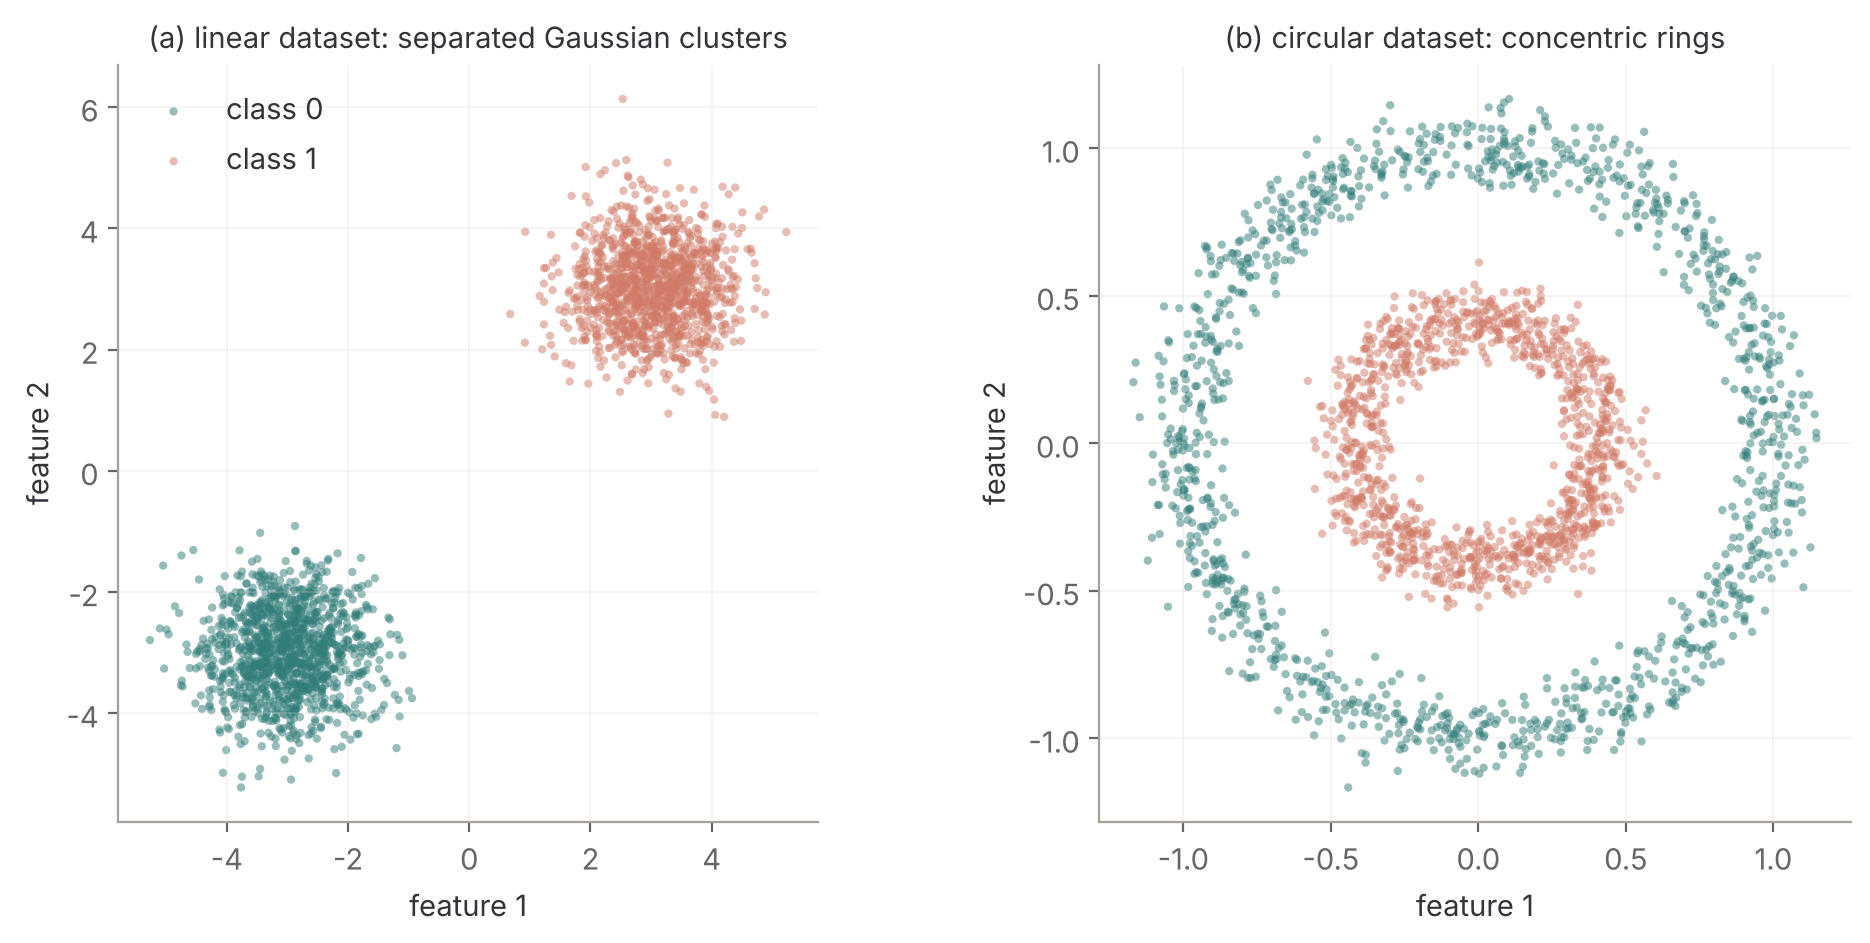

errors of x1+x2=0: 0


In [2]:
N = 10000
X_lin, y_lin = make_blobs(n_samples=N, centers=[(-3, -3), (3, 3)], cluster_std=.70, random_state=SEED)
X_cir, y_cir = make_circles(n_samples=N, factor=.42, noise=.065, random_state=SEED)
print(X_lin.shape, X_cir.shape, np.bincount(y_lin), np.bincount(y_cir))

pd.DataFrame({'X1': X_lin[:, 0], 'X2': X_lin[:, 1], 'Y': y_lin}).to_csv('data/linear_dataset.csv', index=False)
pd.DataFrame({'X1': X_cir[:, 0], 'X2': X_cir[:, 1], 'Y': y_cir}).to_csv('data/circular_dataset.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.6), layout='constrained')
plot_points(axs[0], X_lin, y_lin)
axs[0].set_title('(a) linear dataset: separated Gaussian clusters', fontsize=10.5)
axs[0].set_aspect('equal')
axs[0].legend(loc='upper left', frameon=False)
plot_points(axs[1], X_cir, y_cir)
axs[1].set_title('(b) circular dataset: concentric rings', fontsize=10.5)
axs[1].set_aspect('equal')
save(fig, 'fig01_datasets')

# check that the line x1+x2=0 separates the linear data
errors = ((X_lin.sum(1) > 0).astype(int) != y_lin).sum()
print('errors of x1+x2=0:', errors)
results['q1'] = {'n': N, 'seed': SEED, 'class_counts_linear': np.bincount(y_lin).tolist(),
                 'class_counts_circular': np.bincount(y_cir).tolist(), 'errors_of_line_x1_plus_x2': int(errors)}

# same split for everything after this
XL_tr, XL_te, yl_tr, yl_te = train_test_split(X_lin, y_lin, test_size=.2, stratify=y_lin, random_state=SEED)
XC_tr, XC_te, yc_tr, yc_te = train_test_split(X_cir, y_cir, test_size=.2, stratify=y_cir, random_state=SEED)

## Q2 - perceptron vs linear svm

    dataset       model  accuracy      f1     auc  margin_train  epochs
0    linear  perceptron    1.0000  1.0000  1.0000         1.511     6.0
1    linear  linear SVM    1.0000  1.0000  1.0000         1.571     NaN
2  circular  perceptron    0.5155  0.5224  0.5125           NaN     7.0
3  circular  linear SVM    0.4840  0.4814  0.4835           NaN     NaN


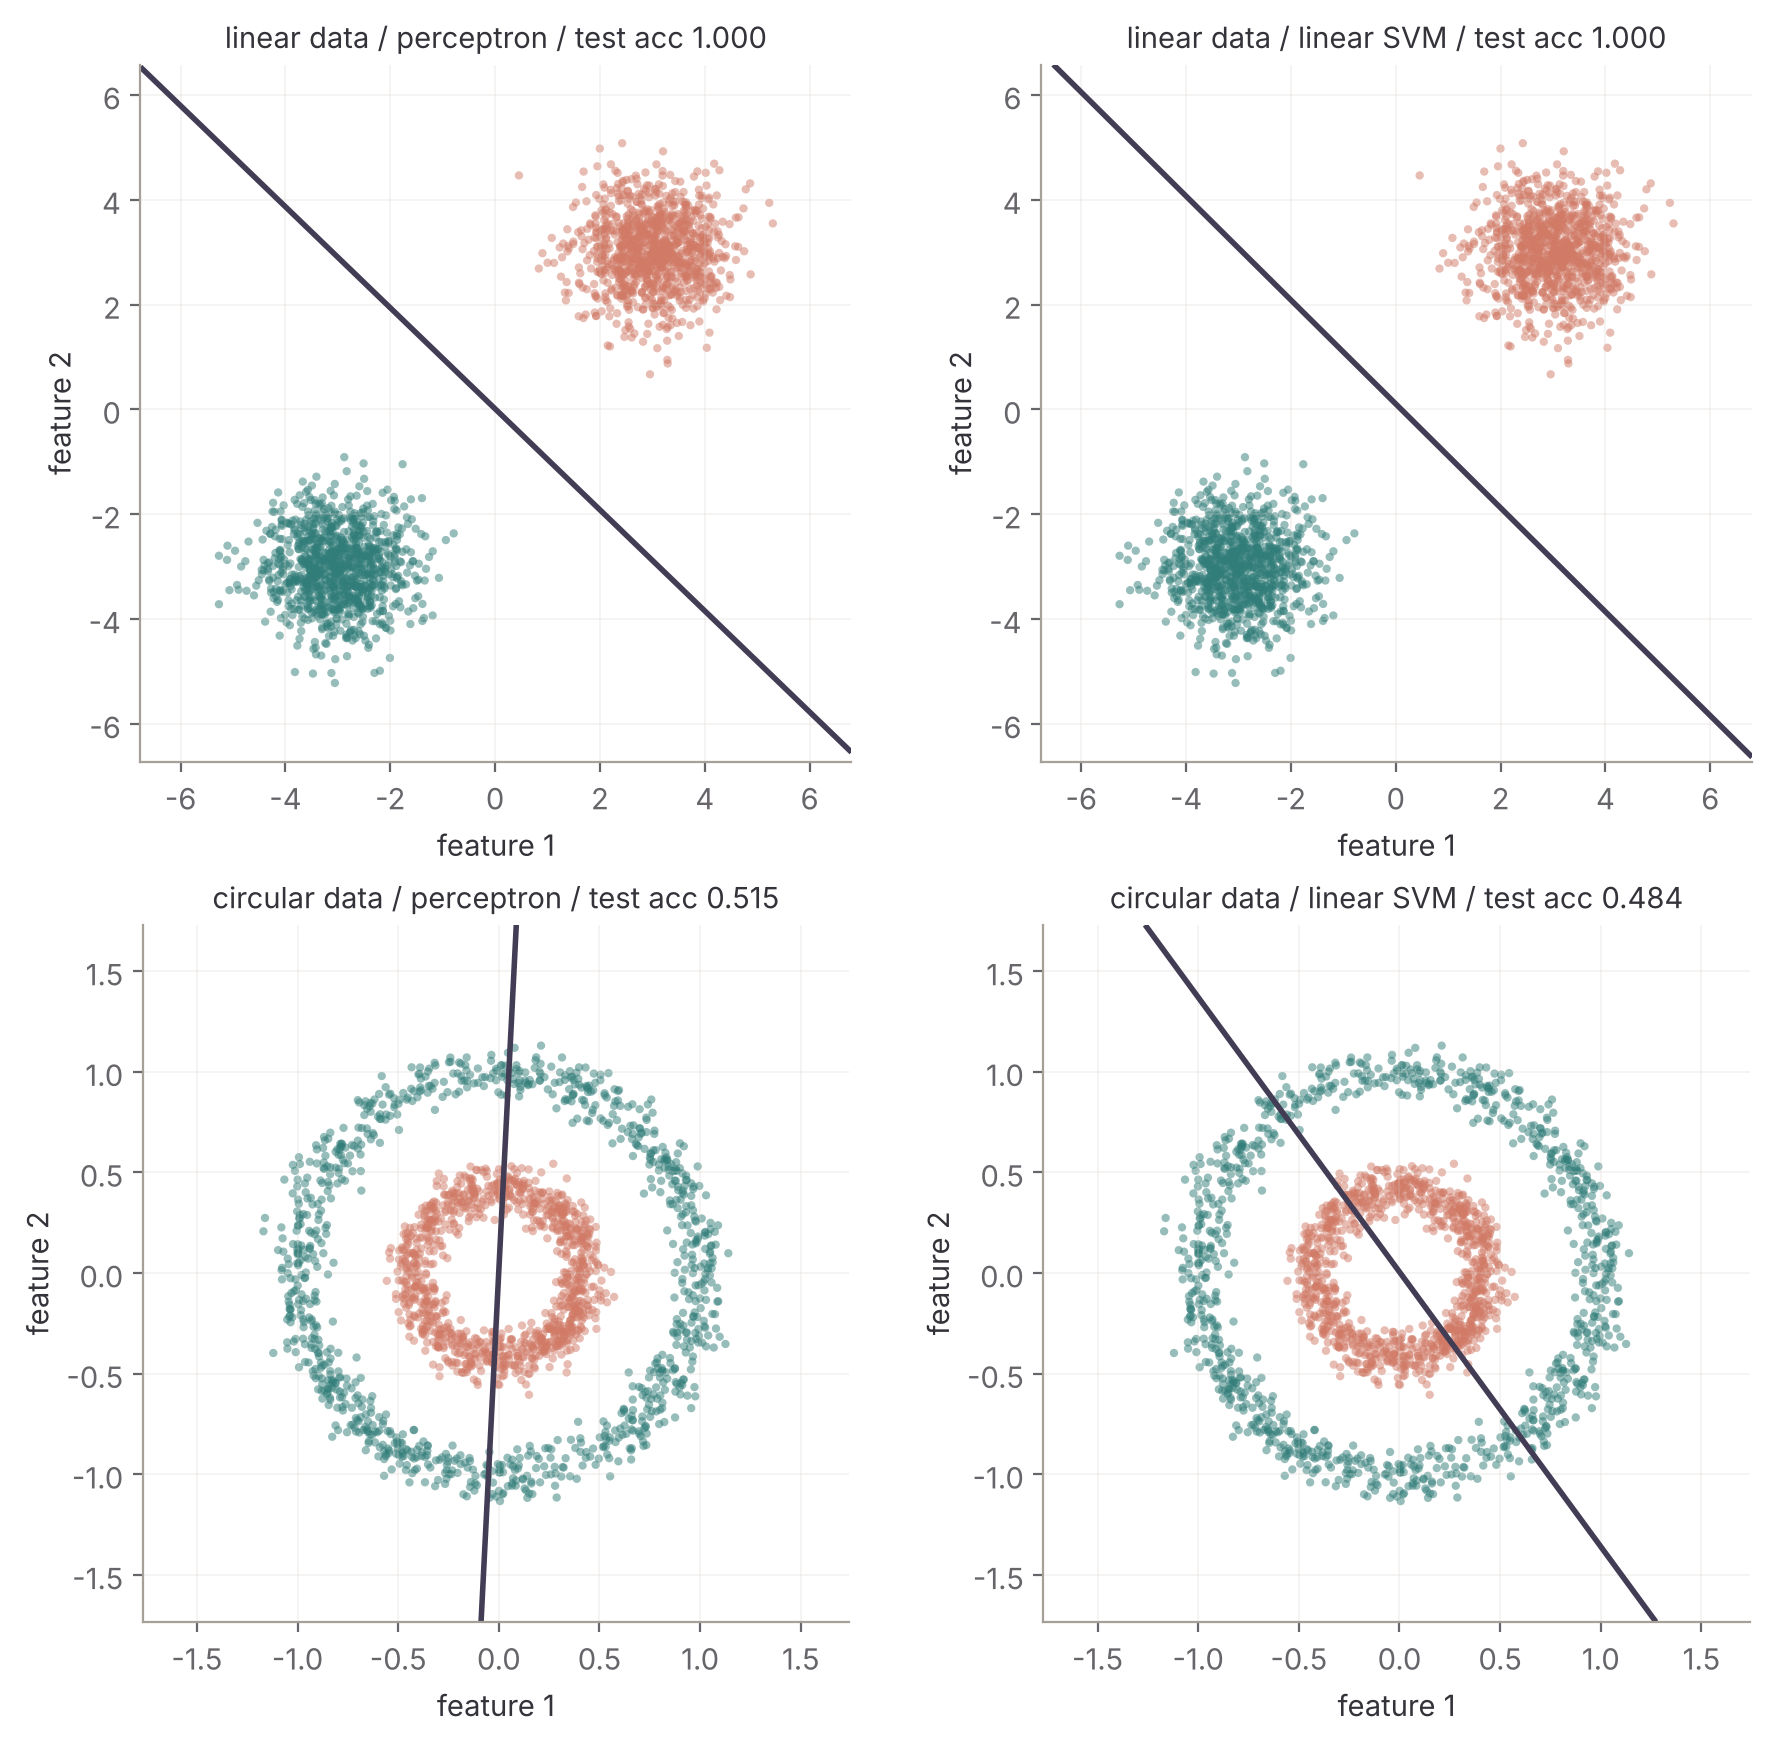

In [3]:
def perceptron(seed=SEED):
    return make_pipeline(StandardScaler(), Perceptron(max_iter=1000, tol=1e-4, random_state=seed))

def lin_svm():
    return make_pipeline(StandardScaler(), LinearSVC(C=1, max_iter=20000, random_state=SEED))

# distance from the closest point to the line (in original units, so we undo the scaler)
def margin(model, X):
    sc = model[0]
    clf = model[-1]
    w = clf.coef_.ravel() / sc.scale_
    b = clf.intercept_[0] - np.sum(clf.coef_.ravel() * sc.mean_ / sc.scale_)
    return float(np.min(np.abs(X @ w + b)) / np.linalg.norm(w))

q2 = []
models2 = {}
for name, Xtr, Xte, ytr, yte in [('linear', XL_tr, XL_te, yl_tr, yl_te), ('circular', XC_tr, XC_te, yc_tr, yc_te)]:
    for mname, model in [('perceptron', perceptron()), ('linear SVM', lin_svm())]:
        model.fit(Xtr, ytr)
        models2[(name, mname)] = model
        row = {'dataset': name, 'model': mname, **get_scores(model, Xte, yte)}
        row['margin_train'] = round(margin(model, Xtr), 3) if name == 'linear' else None
        if mname == 'perceptron':
            row['epochs'] = int(model[-1].n_iter_)
        q2.append(row)
print(pd.DataFrame(q2).drop(columns='confusion_matrix'))
results['q2'] = q2

fig, axs = plt.subplots(2, 2, figsize=(9, 8.6), layout='constrained')
i = 0
for name, Xte, yte in [('linear', XL_te, yl_te), ('circular', XC_te, yc_te)]:
    j = 0
    for mname in ['perceptron', 'linear SVM']:
        acc = [r['accuracy'] for r in q2 if r['dataset'] == name and r['model'] == mname][0]
        plot_boundary(axs[i, j], models2[(name, mname)], Xte, yte, f'{name} data / {mname} / test acc {acc:.3f}')
        j += 1
    i += 1
save(fig, 'fig02_perceptron_vs_svm')

perceptron margins: [0.425 0.4   1.525 1.508 1.52  1.534 0.031 1.352 1.463 1.564 1.531 1.489
 1.545 1.497 1.475 0.059 1.536 1.522 1.527 1.565]
svm margin: 1.571


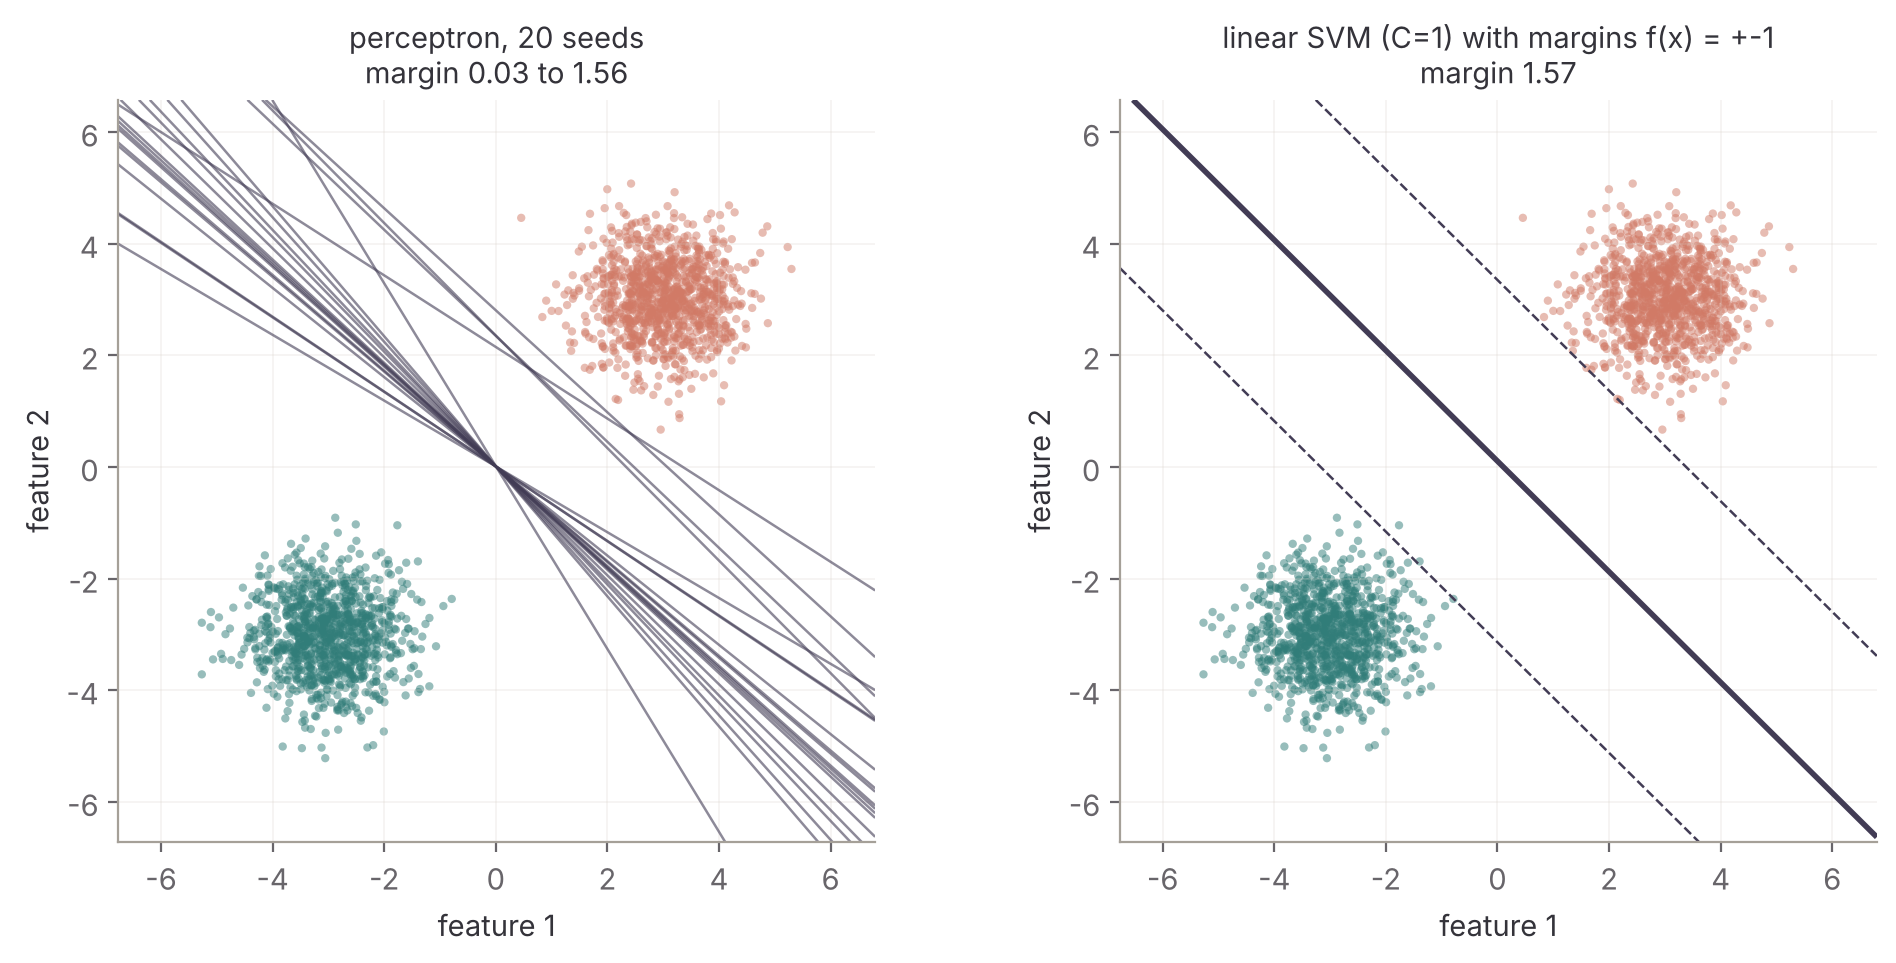

In [4]:
# both are 100% on linear data so lets look at the margin.
# perceptron with 20 different seeds (seed = order of the points), svm has only one solution
perc20 = []
margins20 = []
for s in range(20):
    p = perceptron(s).fit(XL_tr, yl_tr)
    perc20.append(p)
    margins20.append(margin(p, XL_tr))
svm_l = models2[('linear', 'linear SVM')]
svm_marg = margin(svm_l, XL_tr)
print('perceptron margins:', np.round(margins20, 3))
print('svm margin:', round(svm_marg, 3))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.7), layout='constrained')
plot_points(axs[0], XL_te, yl_te)
xx, yy, _ = get_grid(svm_l, XL_te, 1.5)
for p in perc20:
    z = p.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axs[0].contour(xx, yy, z, levels=[0], colors=[INK], linewidths=.9, alpha=.6)
axs[0].set_title(f'perceptron, 20 seeds\nmargin {min(margins20):.2f} to {max(margins20):.2f}', fontsize=10.5)
axs[0].set_aspect('equal')
plot_boundary(axs[1], svm_l, XL_te, yl_te, f'linear SVM (C=1) with margins f(x) = +-1\nmargin {svm_marg:.2f}', margins=True)
save(fig, 'fig03_margin_stability')
results['q2_margin'] = {'perceptron_margins': [round(m, 3) for m in margins20],
                        'perceptron_margin_mean': round(float(np.mean(margins20)), 3), 'svm_margin': round(svm_marg, 3)}

perceptron acc mean/min/max 0.904975 0.856 0.9285
svm acc 0.925  true line acc 0.9255


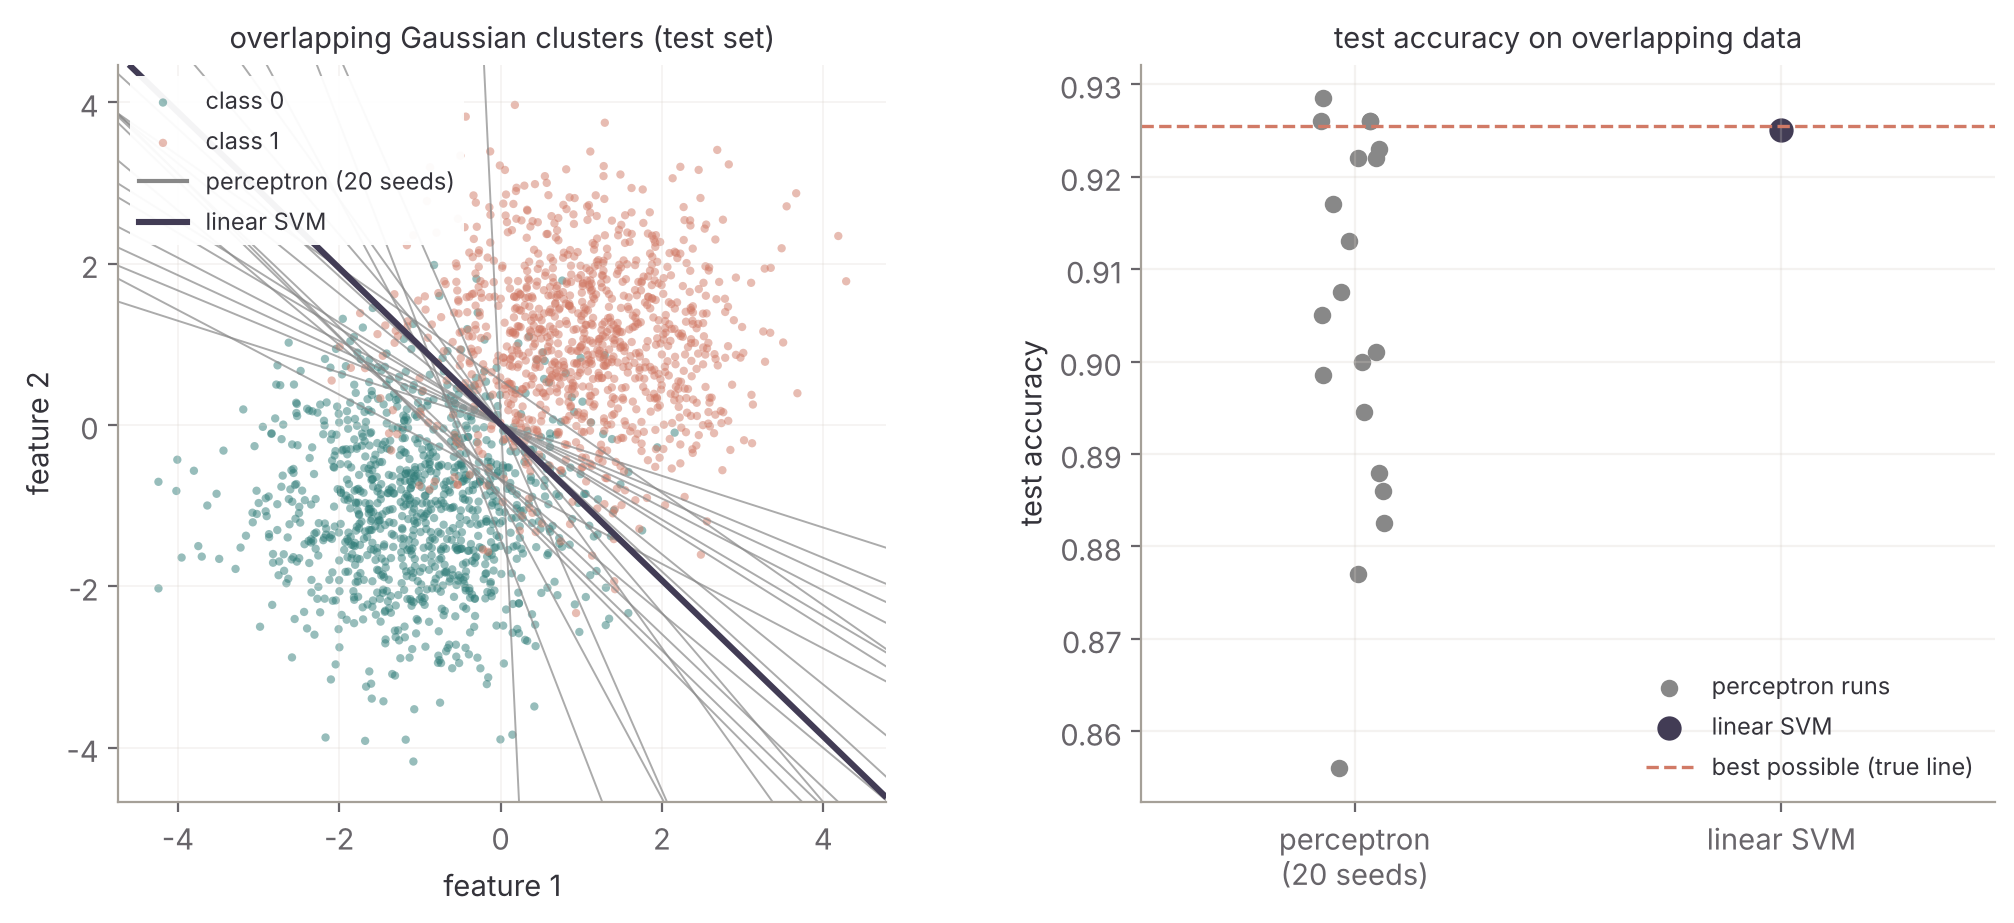

In [5]:
# what if the clusters overlap a bit? no perfect line anymore
X_ov, y_ov = make_blobs(n_samples=N, centers=[(-1, -1), (1, 1)], cluster_std=1.0, random_state=SEED)
XO_tr, XO_te, yo_tr, yo_te = train_test_split(X_ov, y_ov, test_size=.2, stratify=y_ov, random_state=SEED)

perc_ov = [perceptron(s).fit(XO_tr, yo_tr) for s in range(20)]
perc_ov_acc = [accuracy_score(yo_te, p.predict(XO_te)) for p in perc_ov]
svm_ov = lin_svm().fit(XO_tr, yo_tr)
svm_ov_acc = accuracy_score(yo_te, svm_ov.predict(XO_te))
true_line_acc = accuracy_score(yo_te, (XO_te.sum(1) > 0).astype(int))  # the real boundary x1+x2=0
print('perceptron acc mean/min/max', np.mean(perc_ov_acc), np.min(perc_ov_acc), np.max(perc_ov_acc))
print('svm acc', svm_ov_acc, ' true line acc', true_line_acc)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), layout='constrained', gridspec_kw={'width_ratios': [1.15, 1]})
plot_points(axs[0], XO_te, yo_te)
xx, yy, z = get_grid(svm_ov, XO_te, .5)
for p in perc_ov:
    zp = p.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axs[0].contour(xx, yy, zp, levels=[0], colors=['#888888'], linewidths=.7, alpha=.7)
axs[0].contour(xx, yy, z, levels=[0], colors=[INK], linewidths=2.2)
axs[0].plot([], [], color='#888888', label='perceptron (20 seeds)')
axs[0].plot([], [], color=INK, linewidth=2.2, label='linear SVM')
axs[0].legend(frameon=True, framealpha=.95, edgecolor='none', loc='upper left', fontsize=8.5)
axs[0].set_title('overlapping Gaussian clusters (test set)', fontsize=10.5)
axs[0].set_aspect('equal')
jit = np.random.default_rng(0).uniform(-.08, .08, len(perc_ov_acc))
axs[1].scatter(np.zeros(len(perc_ov_acc)) + jit, perc_ov_acc, color='#888888', s=28, label='perceptron runs')
axs[1].scatter([1], [svm_ov_acc], color=INK, s=60, label='linear SVM')
axs[1].axhline(true_line_acc, color=COLORS[1], linestyle='--', linewidth=1.2, label='best possible (true line)')
axs[1].set_xticks([0, 1], ['perceptron\n(20 seeds)', 'linear SVM'])
axs[1].set_xlim(-.5, 1.5)
axs[1].set_ylabel('test accuracy')
axs[1].set_title('test accuracy on overlapping data', fontsize=10.5)
axs[1].legend(frameon=False, fontsize=8.5, loc='lower right')
axs[1].grid(alpha=.25)
save(fig, 'fig04_overlap')
results['q2_overlap'] = {'perceptron_acc_mean': round(float(np.mean(perc_ov_acc)), 4),
                         'perceptron_acc_min': round(float(np.min(perc_ov_acc)), 4),
                         'perceptron_acc_max': round(float(np.max(perc_ov_acc)), 4),
                         'svm_acc': round(float(svm_ov_acc), 4), 'bayes_line_acc': round(float(true_line_acc), 4)}

## Q3 - kernels (rbf vs poly)
cv on 2400 train points (full 8000 was slow), then refit on all train and test once

rbf {'svc__C': 0.1, 'svc__gamma': 0.1} 1.0


poly {'svc__C': 0.1, 'svc__coef0': 1, 'svc__degree': 2, 'svc__gamma': 'scale'} 1.0
  kernel  cv_f1                                        best_params  \
0    rbf    1.0                           {'C': 0.1, 'gamma': 0.1}   
1   poly    1.0  {'C': 0.1, 'coef0': 1, 'degree': 2, 'gamma': '...   

   n_support_vectors  fit_time_s  accuracy   f1  auc  
0                980       0.145       1.0  1.0  1.0  
1                173       0.029       1.0  1.0  1.0  
we use: poly


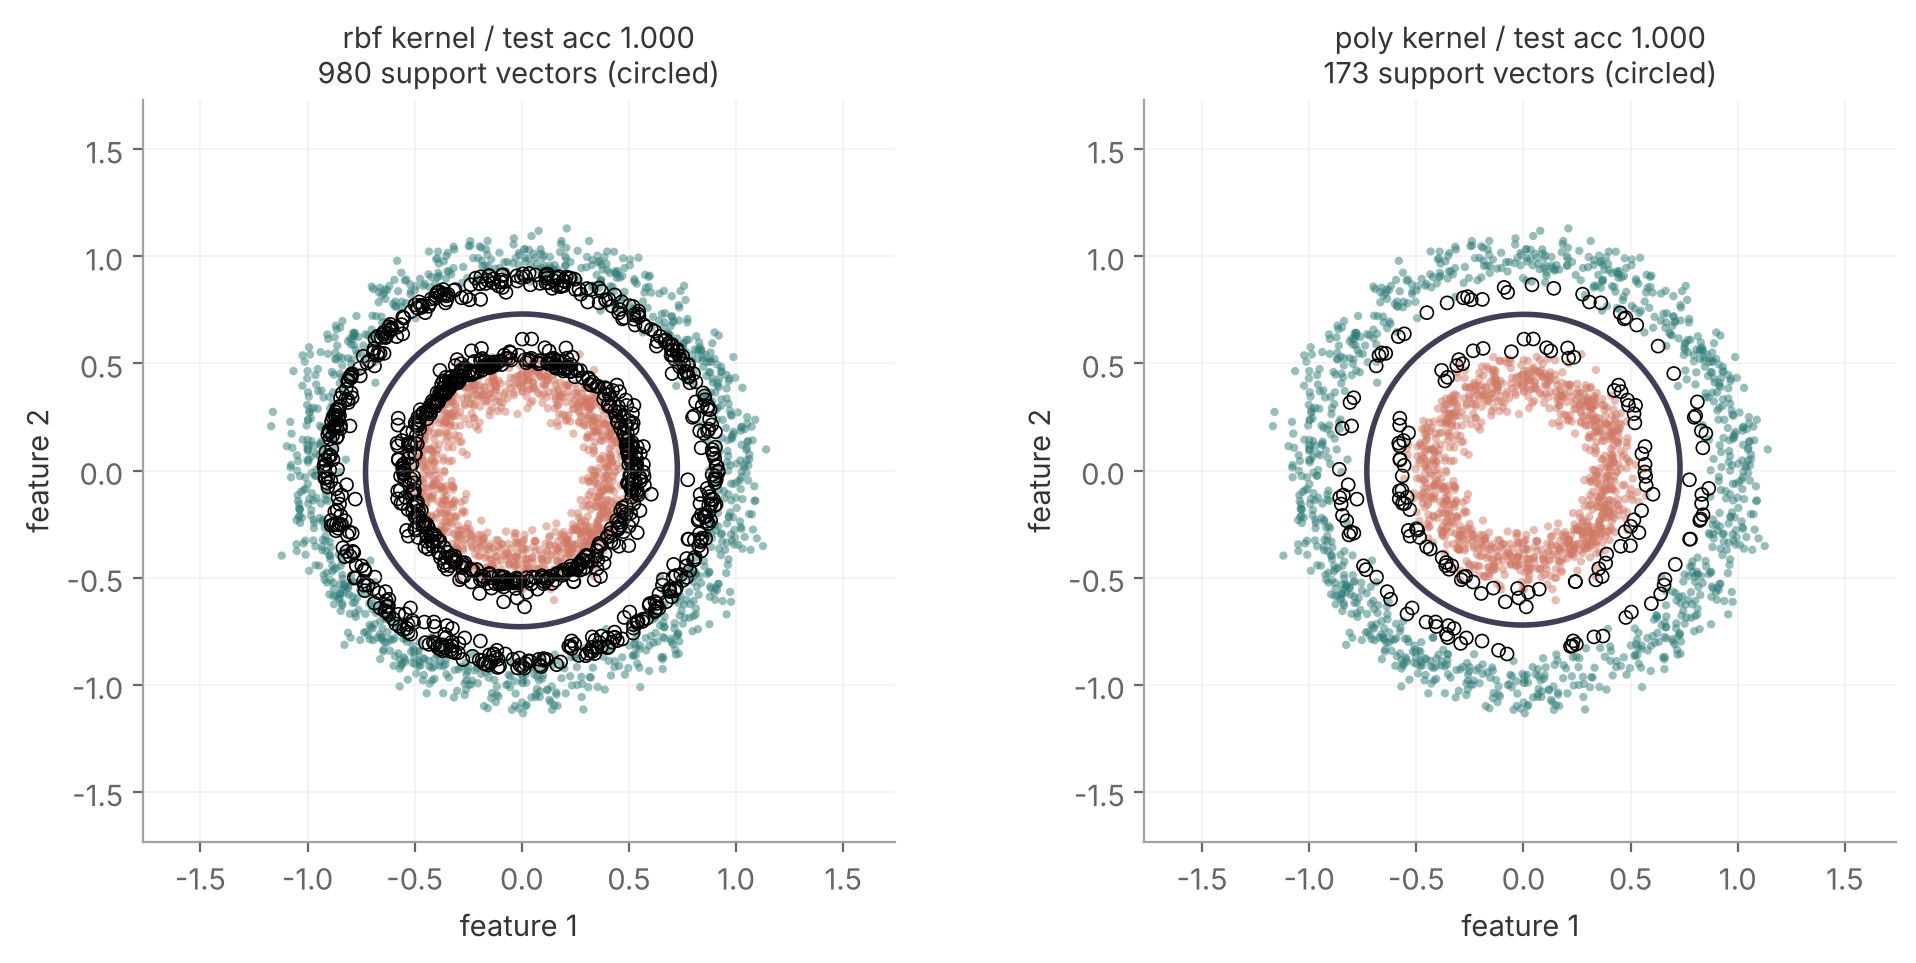

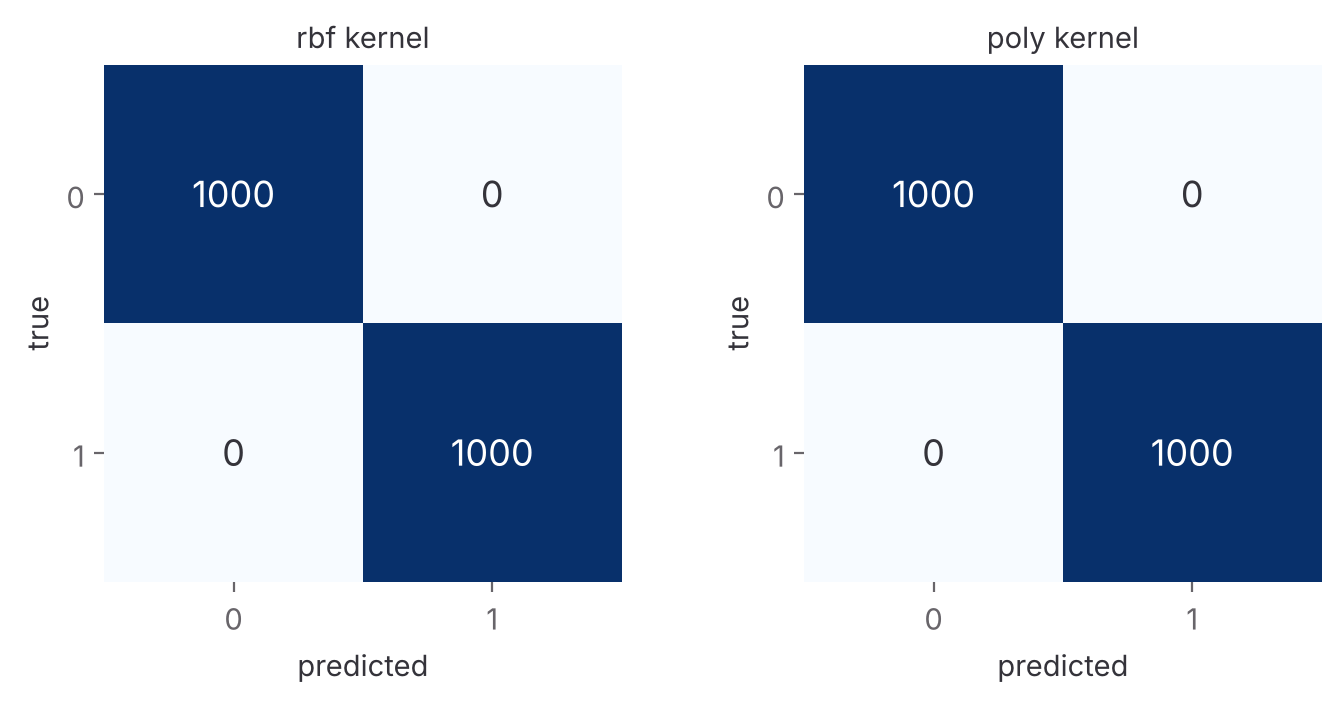

In [6]:
rbf_grid = {'svc__C': [0.1, 1, 10, 100], 'svc__gamma': [0.1, 0.5, 1, 5]}
poly_grid = {'svc__C': [0.1, 1, 10, 100], 'svc__degree': [2, 3, 4], 'svc__coef0': [1], 'svc__gamma': ['scale']}
cv_ids, _ = train_test_split(np.arange(len(yc_tr)), train_size=2400, stratify=yc_tr, random_state=SEED)

q3 = []
kernel_models = {}
for kernel, grid in [('rbf', rbf_grid), ('poly', poly_grid)]:
    gs = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel=kernel)), grid, cv=3, scoring='f1')
    gs.fit(XC_tr[cv_ids], yc_tr[cv_ids])
    print(kernel, gs.best_params_, gs.best_score_)
    model = clone(gs.best_estimator_)
    t = time.perf_counter()
    model.fit(XC_tr, yc_tr)
    t = time.perf_counter() - t
    kernel_models[kernel] = model
    params = {}
    for k, v in gs.best_params_.items():
        params[k.replace('svc__', '')] = v
    q3.append({'kernel': kernel, 'cv_f1': round(float(gs.best_score_), 4), 'best_params': params,
               'n_support_vectors': len(model[-1].support_), 'fit_time_s': round(t, 3),
               **get_scores(model, XC_te, yc_te)})
print(pd.DataFrame(q3).drop(columns='confusion_matrix'))

# both get cv f1 = 1 so we take the one with less support vectors (simpler model)
if round(q3[0]['cv_f1'], 3) == round(q3[1]['cv_f1'], 3):
    best_name = min(q3, key=lambda r: r['n_support_vectors'])['kernel']
else:
    best_name = max(q3, key=lambda r: r['cv_f1'])['kernel']
best_svm = kernel_models[best_name]
print('we use:', best_name)

fig, axs = plt.subplots(1, 2, figsize=(10, 4.7), layout='constrained')
for ax, r in zip(axs, q3):
    m = kernel_models[r['kernel']]
    plot_boundary(ax, m, XC_te, yc_te,
                  f"{r['kernel']} kernel / test acc {r['accuracy']:.3f}\n{r['n_support_vectors']} support vectors (circled)",
                  sv=XC_tr[m[-1].support_])
save(fig, 'fig05_kernels')

# confusion matrices
fig, axs = plt.subplots(1, 2, figsize=(7, 3.4), layout='constrained')
for ax, r in zip(axs, q3):
    cm = np.array(r['confusion_matrix'])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.sum() / 2)
    for a in range(2):
        for b in range(2):
            ax.text(b, a, str(cm[a, b]), ha='center', va='center', fontsize=13,
                    color='white' if cm[a, b] > cm.sum() / 4 else '#34333A')
    ax.set_xticks([0, 1], ['0', '1'])
    ax.set_yticks([0, 1], ['0', '1'])
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_title(r['kernel'] + ' kernel', fontsize=10.5)
    ax.spines[:].set_visible(False)
save(fig, 'fig06_confusion')
results['q3'] = q3
results['q3_chosen_kernel'] = best_name

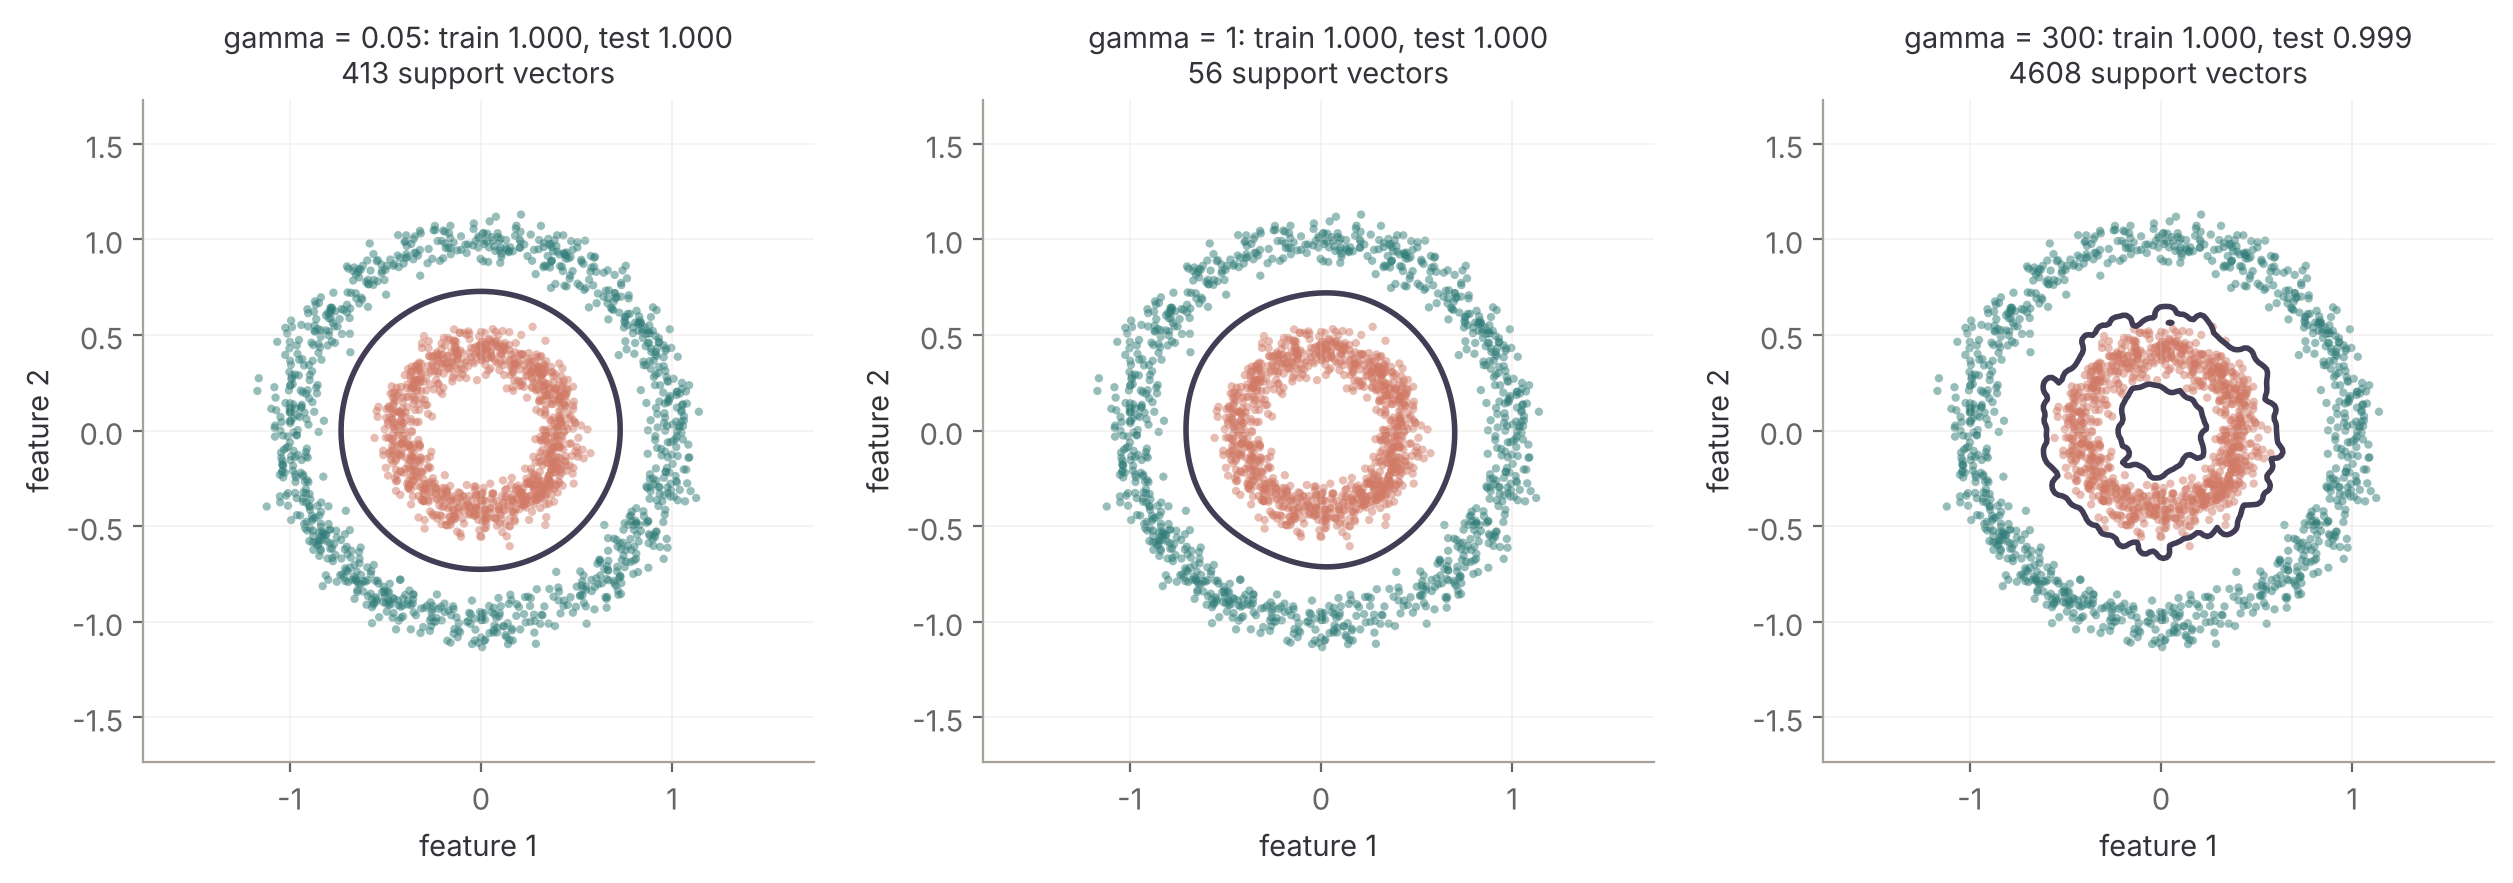

    gamma  train_acc  test_acc  n_support_vectors
0    0.05        1.0    1.0000                413
1    1.00        1.0    1.0000                 56
2  300.00        1.0    0.9985               4608


In [7]:
# trying different gammas for rbf to see what it does (C=1 here, not from the cv)
gamma_res = []
fig, axs = plt.subplots(1, 3, figsize=(12.6, 4.3), layout='constrained')
for ax, g in zip(axs, [0.05, 1, 300]):
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1, gamma=g)).fit(XC_tr, yc_tr)
    tr_acc = get_scores(m, XC_tr, yc_tr)['accuracy']
    te_acc = get_scores(m, XC_te, yc_te)['accuracy']
    nsv = len(m[-1].support_)
    gamma_res.append({'gamma': g, 'train_acc': tr_acc, 'test_acc': te_acc, 'n_support_vectors': nsv})
    plot_boundary(ax, m, XC_te, yc_te, f'gamma = {g:g}: train {tr_acc:.3f}, test {te_acc:.3f}\n{nsv} support vectors')
save(fig, 'fig07_gamma')
print(pd.DataFrame(gamma_res))
results['q3_gamma'] = gamma_res

### Q3 extra - harder rings
on the clean rings everything is 100% so we also tried overlapping rings, 10 different splits

       accuracy              f1             auc         n_support_vectors  \
           mean     std    mean     std    mean     std              mean   
kernel                                                                      
poly     0.8516  0.0098  0.8524  0.0106  0.9297  0.0069             826.5   
rbf      0.8516  0.0108  0.8511  0.0123  0.9298  0.0075            1011.4   

                  
             std  
kernel            
poly     14.2224  
rbf     153.4957  
rbf - poly per split: [-0.0013, 0.004, 0.0, 0.0, -0.0053, 0.0, 0.0, 0.0053, 0.0, -0.0027]
rbf wins 2 poly wins 3 ties 5


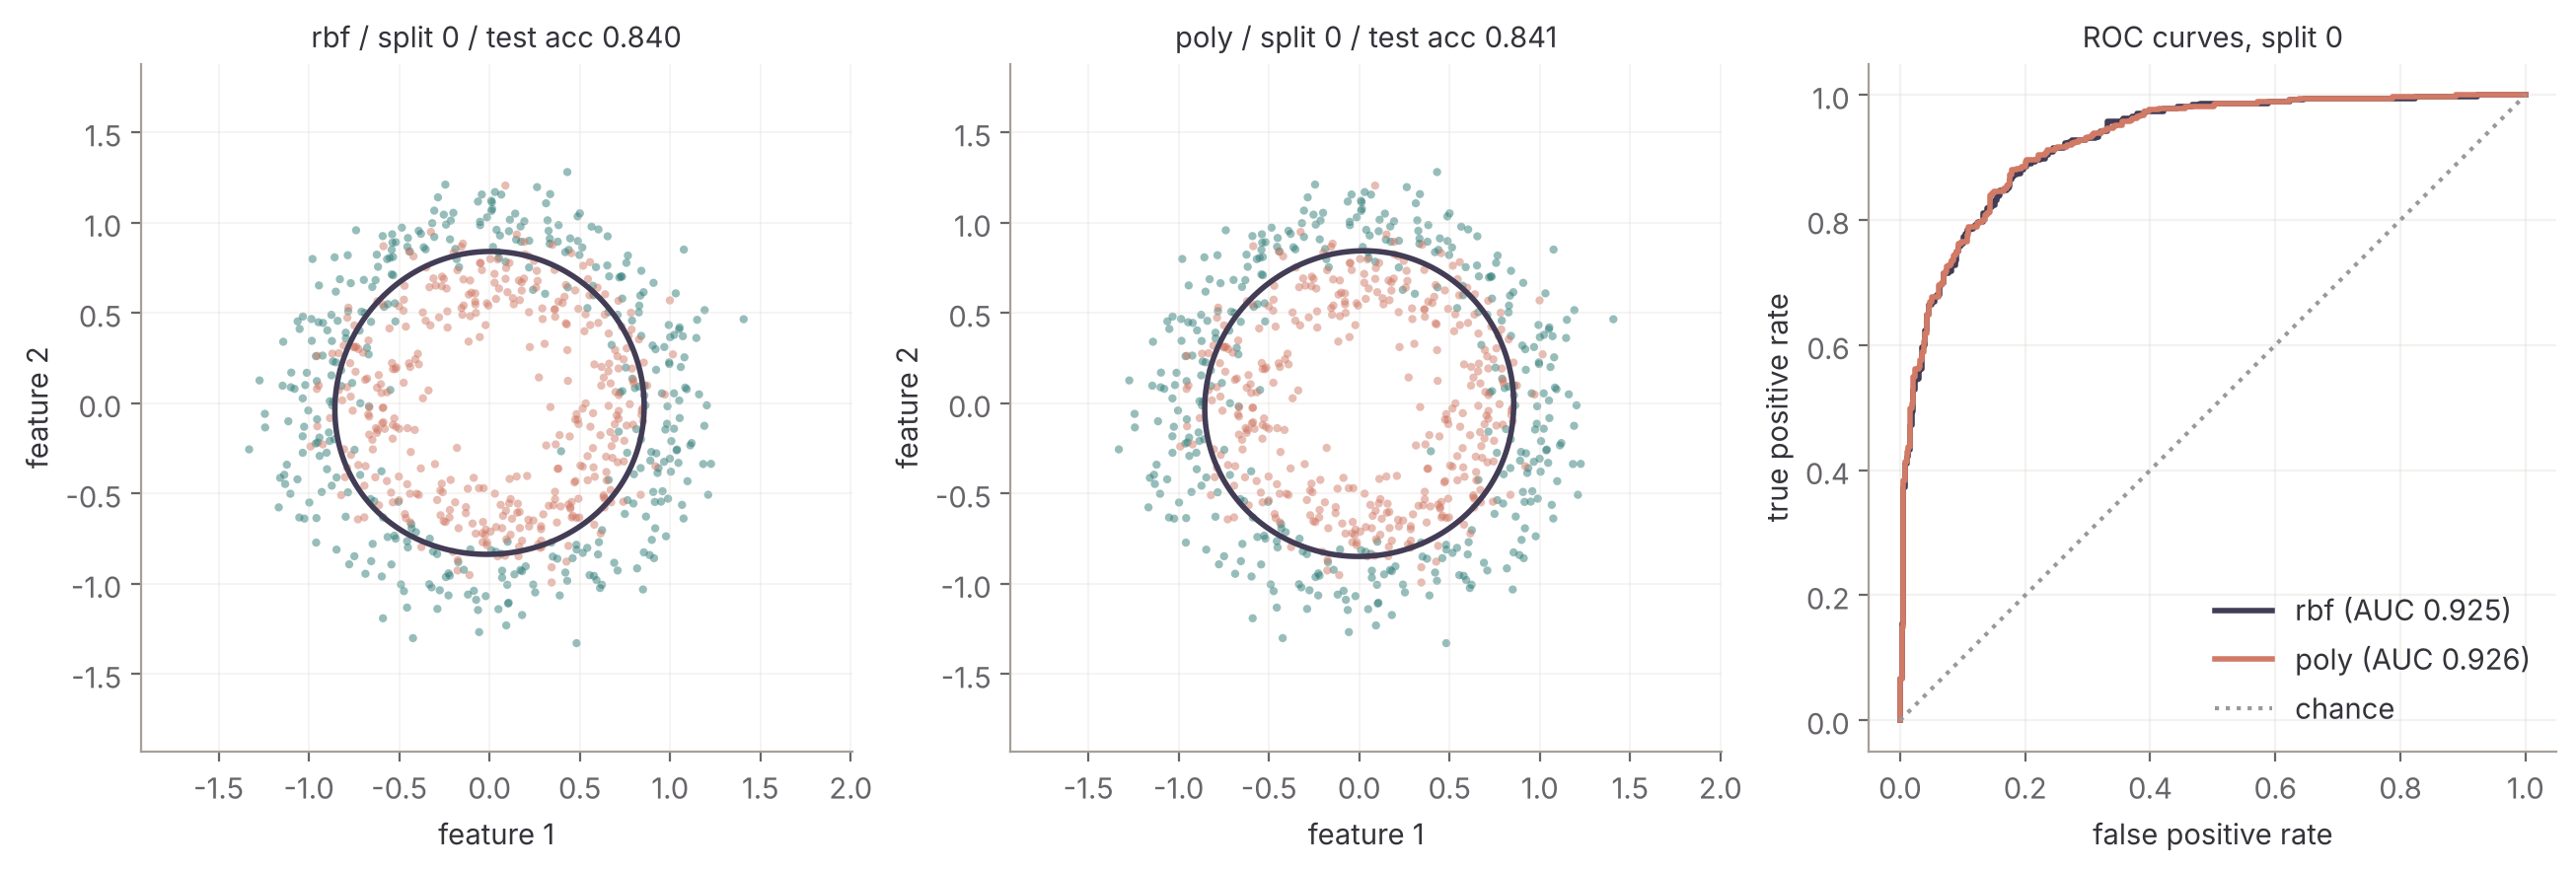

In [8]:
X_hard, y_hard = make_circles(n_samples=3000, factor=.68, noise=.15, random_state=79)
rbf_grid2 = {'svc__C': [0.3, 3, 30], 'svc__gamma': [0.2, 1, 5]}
poly_grid2 = {'svc__C': [0.3, 3, 30], 'svc__degree': [2, 3, 4], 'svc__coef0': [1], 'svc__gamma': ['scale']}

hard = []
hard_models = {}
for split in range(10):
    a, b, c, d = train_test_split(X_hard, y_hard, test_size=.25, stratify=y_hard, random_state=split)
    if split == 0:
        Xh_tr, Xh_te, yh_tr, yh_te = a, b, c, d   # keep split 0 for plots and q4
    for kernel, grid in [('rbf', rbf_grid2), ('poly', poly_grid2)]:
        gs = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel=kernel)), grid, cv=3, scoring='f1')
        gs.fit(a, c)
        m = gs.best_estimator_
        params = {}
        for k, v in gs.best_params_.items():
            params[k.replace('svc__', '')] = v
        hard.append({'split': split, 'kernel': kernel, **get_scores(m, b, d),
                     'n_support_vectors': len(m[-1].support_), 'best_params': params})
        if split == 0:
            hard_models[kernel] = m

hard_df = pd.DataFrame(hard)
summary = hard_df.groupby('kernel')[['accuracy', 'f1', 'auc', 'n_support_vectors']].agg(['mean', 'std']).round(4)
print(summary)
acc = hard_df.pivot(index='split', columns='kernel', values='accuracy')
diff = acc['rbf'] - acc['poly']
print('rbf - poly per split:', diff.round(4).tolist())
print('rbf wins', (diff > 0).sum(), 'poly wins', (diff < 0).sum(), 'ties', (diff == 0).sum())

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3), layout='constrained')
for ax, kernel in zip(axs[:2], ['rbf', 'poly']):
    a0 = hard_df[(hard_df.split == 0) & (hard_df.kernel == kernel)].accuracy.iloc[0]
    plot_boundary(ax, hard_models[kernel], Xh_te, yh_te, f'{kernel} / split 0 / test acc {a0:.3f}')
for kernel, color in [('rbf', INK), ('poly', COLORS[1])]:
    fpr, tpr, _ = roc_curve(yh_te, hard_models[kernel].decision_function(Xh_te))
    auc0 = hard_df[(hard_df.split == 0) & (hard_df.kernel == kernel)].auc.iloc[0]
    axs[2].plot(fpr, tpr, color=color, linewidth=2, label=f'{kernel} (AUC {auc0:.3f})')
axs[2].plot([0, 1], [0, 1], color='#999999', linestyle=':', label='chance')
axs[2].set_xlabel('false positive rate')
axs[2].set_ylabel('true positive rate')
axs[2].set_title('ROC curves, split 0', fontsize=10.5)
axs[2].legend(frameon=False, loc='lower right')
axs[2].set_aspect('equal')
axs[2].grid(alpha=.25)
save(fig, 'fig08_hard_kernels')

results['q3_hard'] = {'per_split': hard, 'rbf_minus_poly_acc': diff.round(4).tolist(),
                      'summary': {k: {m: {s: float(summary.loc[k, (m, s)]) for s in ['mean', 'std']}
                                      for m in ['accuracy', 'f1', 'auc', 'n_support_vectors']} for k in ['rbf', 'poly']}}
hard_best = hard_models[best_name]

## Q4 - augmentation
repeat k=5000 times: sample 1000 train points -> add gaussian noise to x (labels same) -> train svm -> train acc (on the noisy points) and test acc (clean test).
overfitting = train acc - test acc. noise: none 0, low 0.1, high 0.3. also on the hard rings because clean rings are always 100%

this cell is slow (~15 min)

In [9]:
K = 5000
noise_sd = {'none': 0.0, 'low': 0.10, 'high': 0.30}
setups = {'clean rings': (best_svm, XC_tr, yc_tr, XC_te, yc_te),
          'hard rings': (hard_best, Xh_tr, yh_tr, Xh_te, yh_te)}

q4_runs = {}
q4 = []
start = time.time()
for dname, (base_model, Xp, yp, Xt, yt) in setups.items():
    for ci, (cond, sd) in enumerate(noise_sd.items()):
        out = []
        for rep in range(K):
            rng = np.random.default_rng(10000 * (ci + 1) + rep)
            ids = rng.choice(len(yp), 1000, replace=False)
            X_aug = Xp[ids] + rng.normal(0, sd, (1000, 2))
            m = clone(base_model).fit(X_aug, yp[ids])
            out.append([accuracy_score(yp[ids], m.predict(X_aug)), accuracy_score(yt, m.predict(Xt)), len(m[-1].support_)])
        out = np.array(out)
        q4_runs[(dname, cond)] = out
        gap = out[:, 0] - out[:, 1]
        q4.append({'data': dname, 'augmentation': cond, 'sd': sd, 'k': K,
                   'train_acc_mean': out[:, 0].mean(), 'test_acc_mean': out[:, 1].mean(), 'test_acc_sd': out[:, 1].std(),
                   'test_acc_p05': np.percentile(out[:, 1], 5), 'test_acc_p95': np.percentile(out[:, 1], 95),
                   'gap_mean': gap.mean(), 'gap_sd': gap.std(), 'n_sv_mean': out[:, 2].mean()})
        print(dname, cond, 'done', int(time.time() - start), 'sec')
q4_df = pd.DataFrame(q4).round(4)
print(q4_df)
results['q4'] = q4_df.to_dict('records')

clean rings none done 51 sec


clean rings low done 124 sec


clean rings high done 291 sec


hard rings none done 398 sec


hard rings low done 527 sec


hard rings high done 710 sec
          data augmentation   sd     k  train_acc_mean  test_acc_mean  \
0  clean rings         none  0.0  5000          1.0000         1.0000   
1  clean rings          low  0.1  5000          0.9910         1.0000   
2  clean rings         high  0.3  5000          0.8119         0.9950   
3   hard rings         none  0.0  5000          0.8567         0.8395   
4   hard rings          low  0.1  5000          0.8088         0.8385   
5   hard rings         high  0.3  5000          0.6736         0.7776   

   test_acc_sd  test_acc_p05  test_acc_p95  gap_mean  gap_sd  n_sv_mean  
0       0.0000        1.0000        1.0000    0.0000  0.0000   102.0582  
1       0.0000        1.0000        1.0000   -0.0090  0.0030   184.2456  
2       0.0037        0.9880        0.9990   -0.1831  0.0127   516.3398  
3       0.0040        0.8333        0.8453    0.0172  0.0095   392.5746  
4       0.0050        0.8307        0.8467   -0.0297  0.0125   480.0380  
5       0.0226 

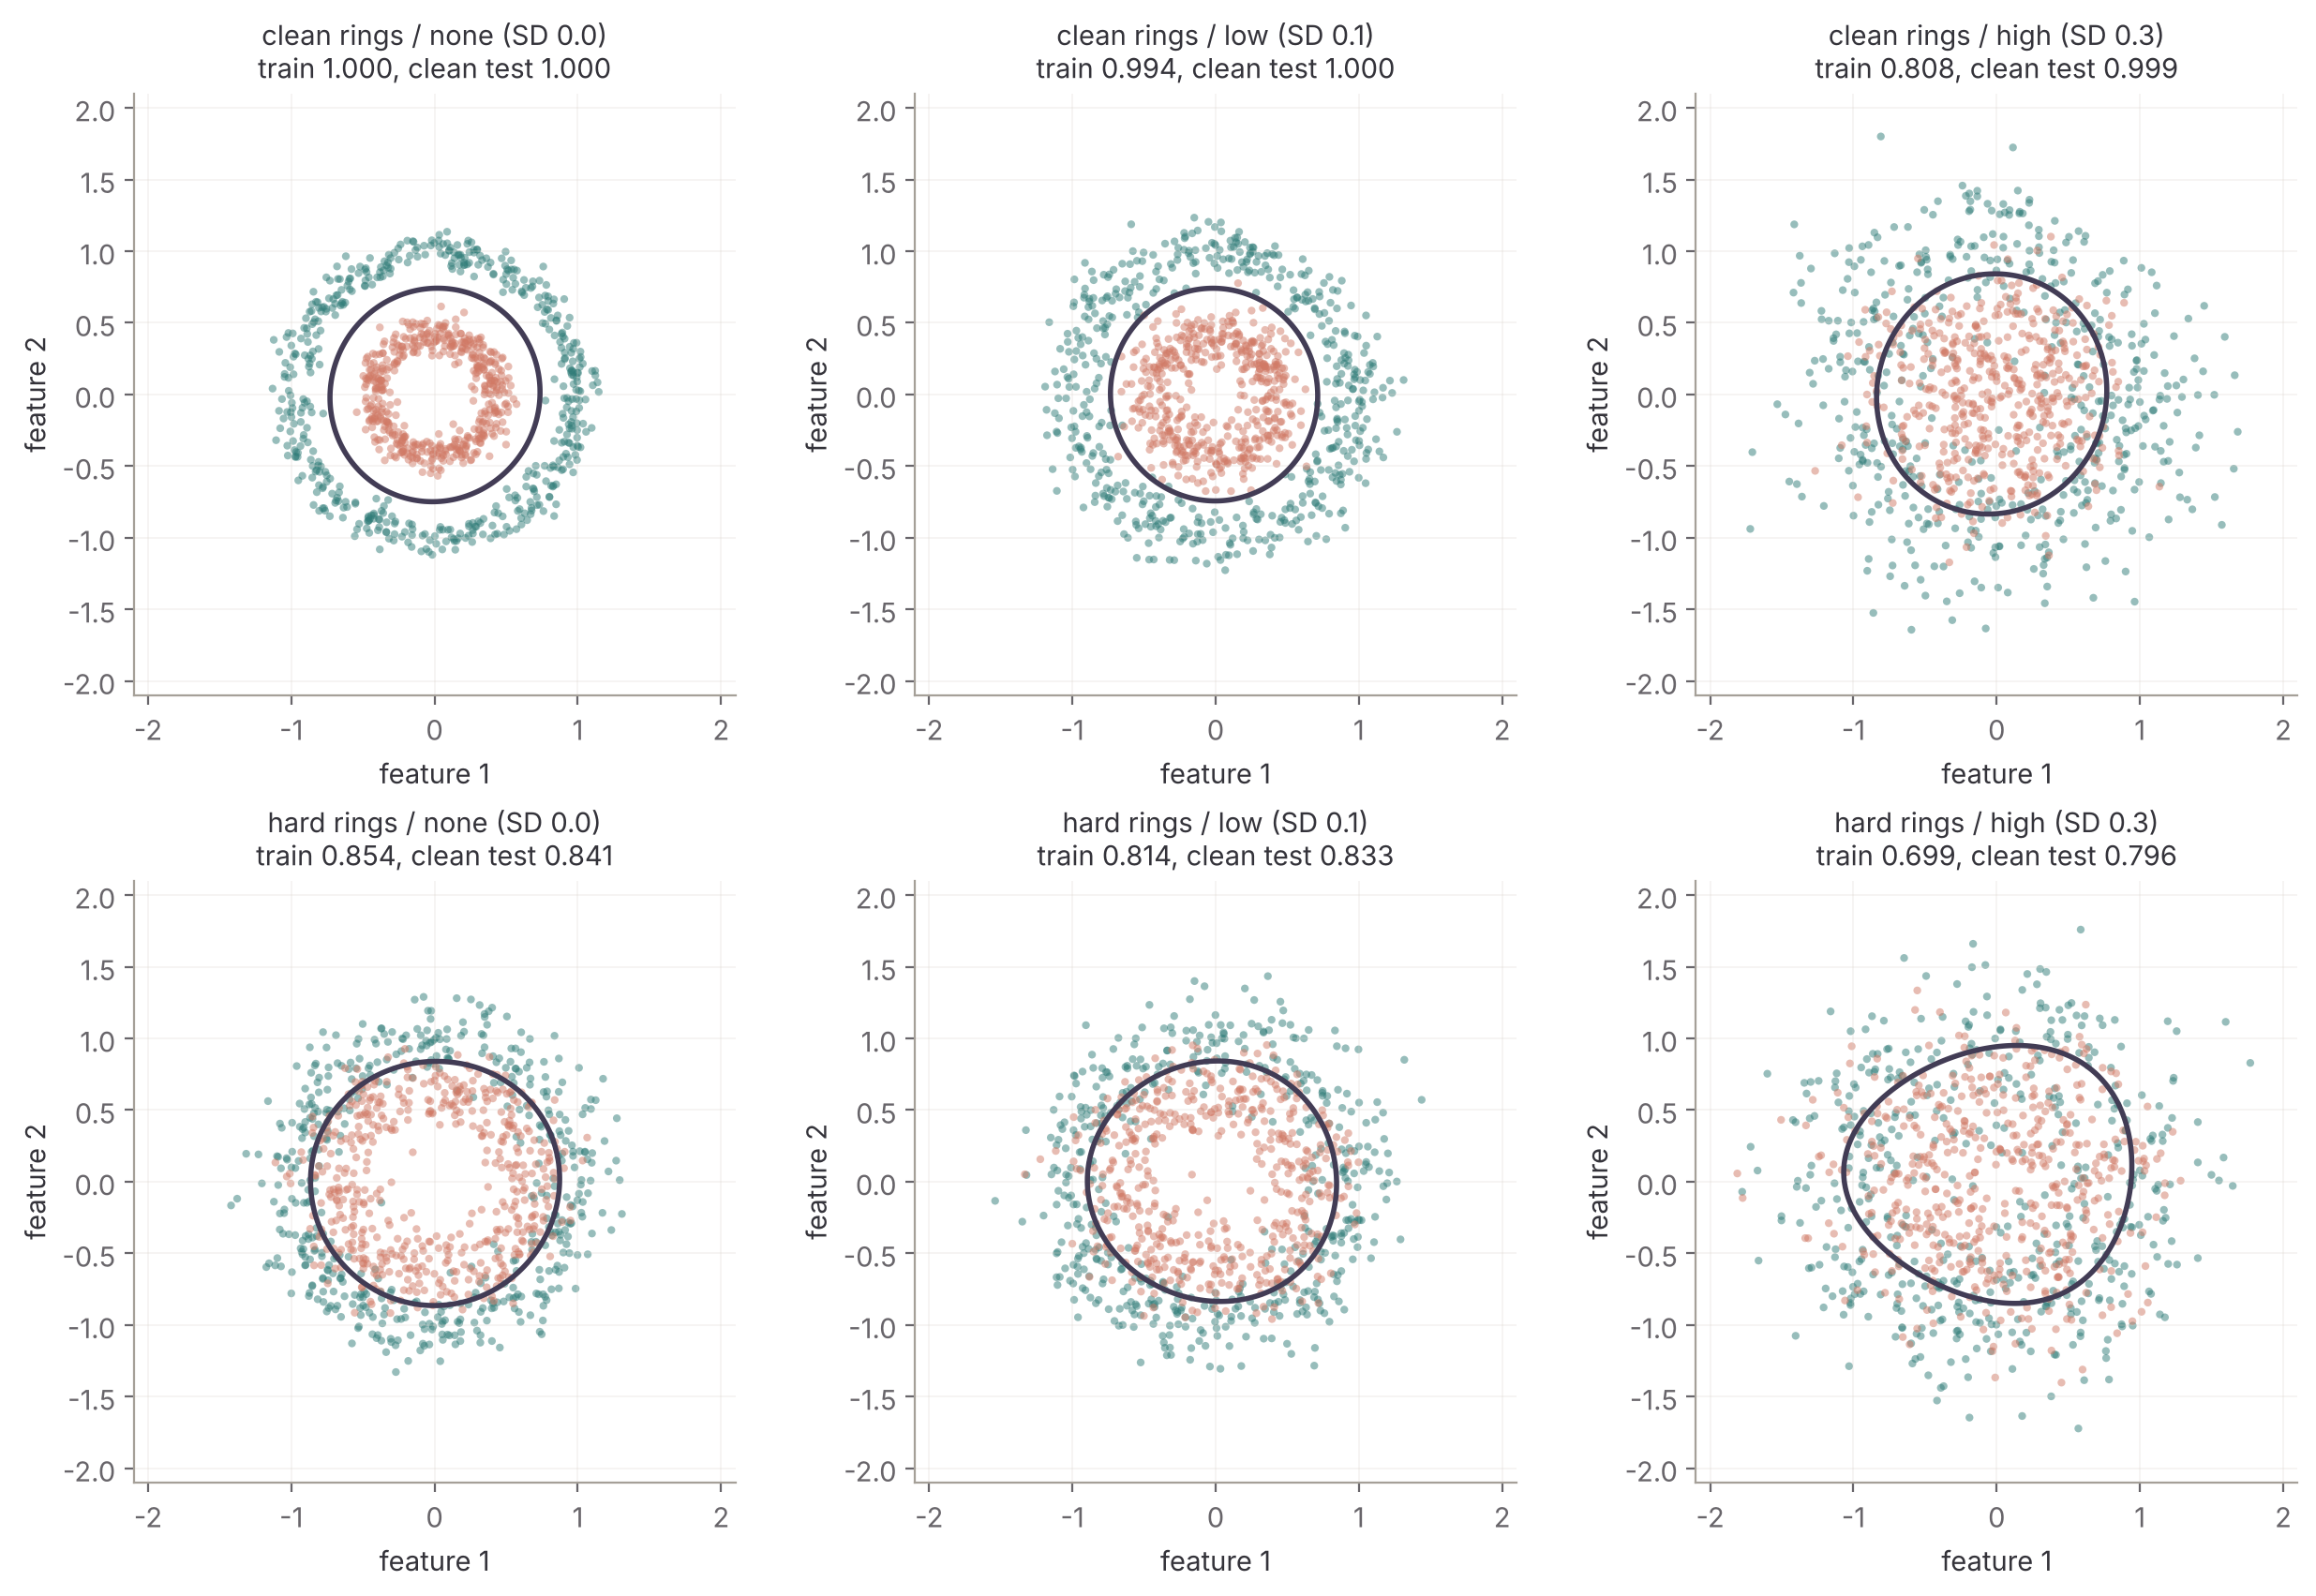

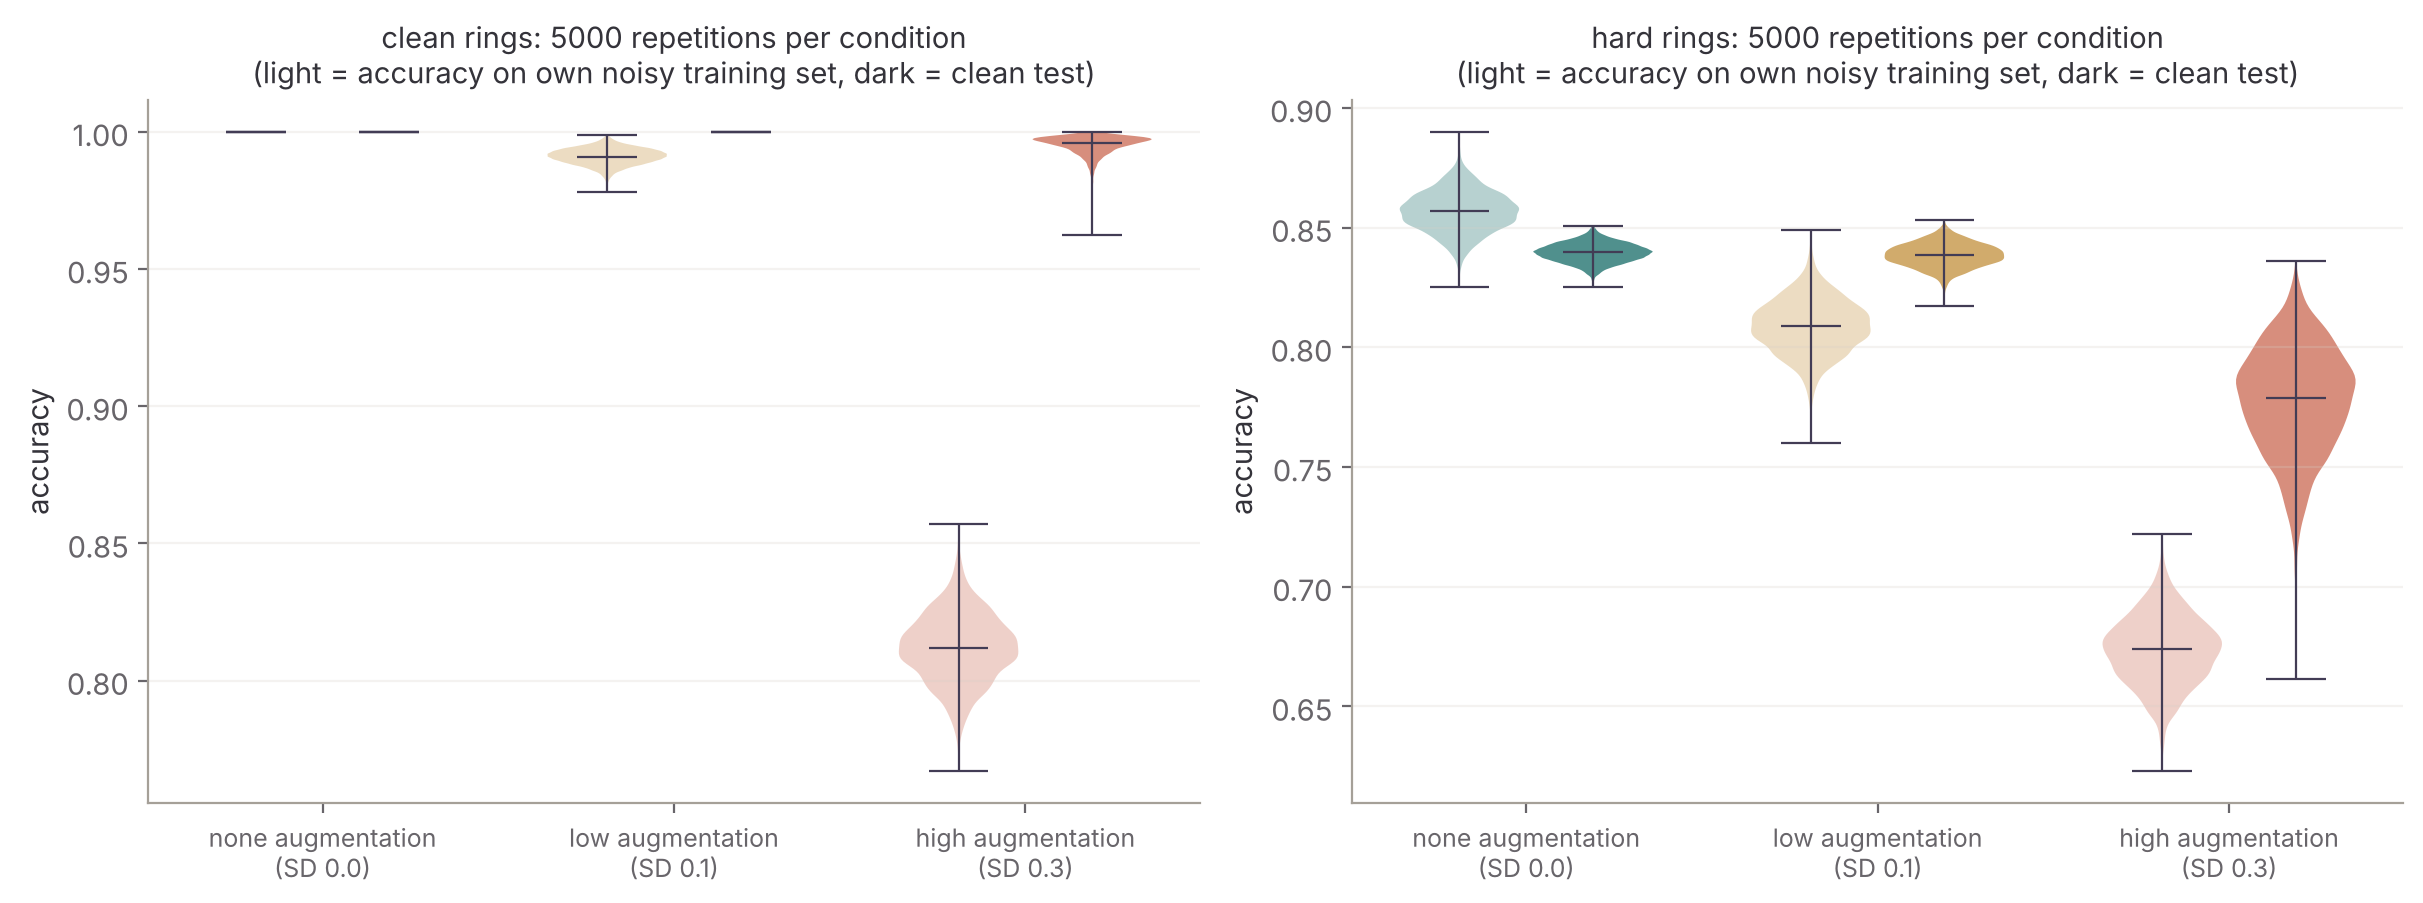

In [10]:
# one example of each augmented set + boundary
fig, axs = plt.subplots(2, 3, figsize=(12.5, 8.4), layout='constrained')
for i, (dname, (base_model, Xp, yp, Xt, yt)) in enumerate(setups.items()):
    for j, (cond, sd) in enumerate(noise_sd.items()):
        rng = np.random.default_rng(2026)
        ids = rng.choice(len(yp), 1000, replace=False)
        X_aug = Xp[ids] + rng.normal(0, sd, (1000, 2))
        m = clone(base_model).fit(X_aug, yp[ids])
        tr = accuracy_score(yp[ids], m.predict(X_aug))
        te = accuracy_score(yt, m.predict(Xt))
        plot_boundary(axs[i, j], m, X_aug, yp[ids], f'{dname} / {cond} (SD {sd})\ntrain {tr:.3f}, clean test {te:.3f}')
        axs[i, j].set_xlim(-2.1, 2.1)
        axs[i, j].set_ylim(-2.1, 2.1)
save(fig, 'fig09_augmentation_examples')

# violin plots train vs test
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
for ax, dname in zip(axs, setups):
    for pos, cond in enumerate(noise_sd):
        out = q4_runs[(dname, cond)]
        for k, alpha in [(0, .35), (1, .85)]:   # 0 = train, 1 = test
            v = ax.violinplot(out[:, k], positions=[pos + .38 * k], widths=.34, showmedians=True)
            for body in v['bodies']:
                body.set_facecolor(COND_COLORS[cond])
                body.set_alpha(alpha)
            for key in ['cmedians', 'cmins', 'cmaxes', 'cbars']:
                v[key].set_color(INK)
                v[key].set_linewidth(.8)
    ax.set_xticks([p + .19 for p in range(3)], [f'{c} augmentation\n(SD {s})' for c, s in noise_sd.items()], fontsize=9)
    ax.set_ylabel('accuracy')
    ax.set_title(f'{dname}: {K} repetitions per condition\n(light = accuracy on own noisy training set, dark = clean test)', fontsize=10.5)
    ax.grid(alpha=.25, axis='y')
save(fig, 'fig10_augmentation_distributions')

## Q5 - wrong labels
shuffle = take p% of the points and mix their labels (only ~half of them really change)
flip = change exactly p% of labels to the other class
only on the original train data, test labels stay correct. 2000 train points, 5 seeds

     dataset   method  pct  wrong  test_mean  test_sd  train_noisy    n_sv
0   circular     flip    0   0.00     1.0000   0.0000       1.0000   121.0
1   circular     flip   10  10.00     1.0000   0.0000       0.9000   568.0
2   circular     flip   15  15.00     1.0000   0.0000       0.8500   781.4
3   circular     flip   20  20.00     1.0000   0.0000       0.8000   984.2
4   circular     flip   25  25.00     1.0000   0.0000       0.7500  1176.0
5   circular     flip   30  30.00     1.0000   0.0000       0.7000  1370.6
6   circular     flip   35  35.00     1.0000   0.0000       0.6500  1551.0
7   circular     flip   40  40.00     0.9997   0.0004       0.5999  1719.4
8   circular     flip   45  45.00     0.9695   0.0592       0.5498  1875.4
9   circular     flip   50  50.00     0.5278   0.1254       0.5105  1962.8
10  circular  shuffle    0   0.00     1.0000   0.0000       1.0000   121.0
11  circular  shuffle   10   5.02     1.0000   0.0000       0.9498   349.0
12  circular  shuffle   1

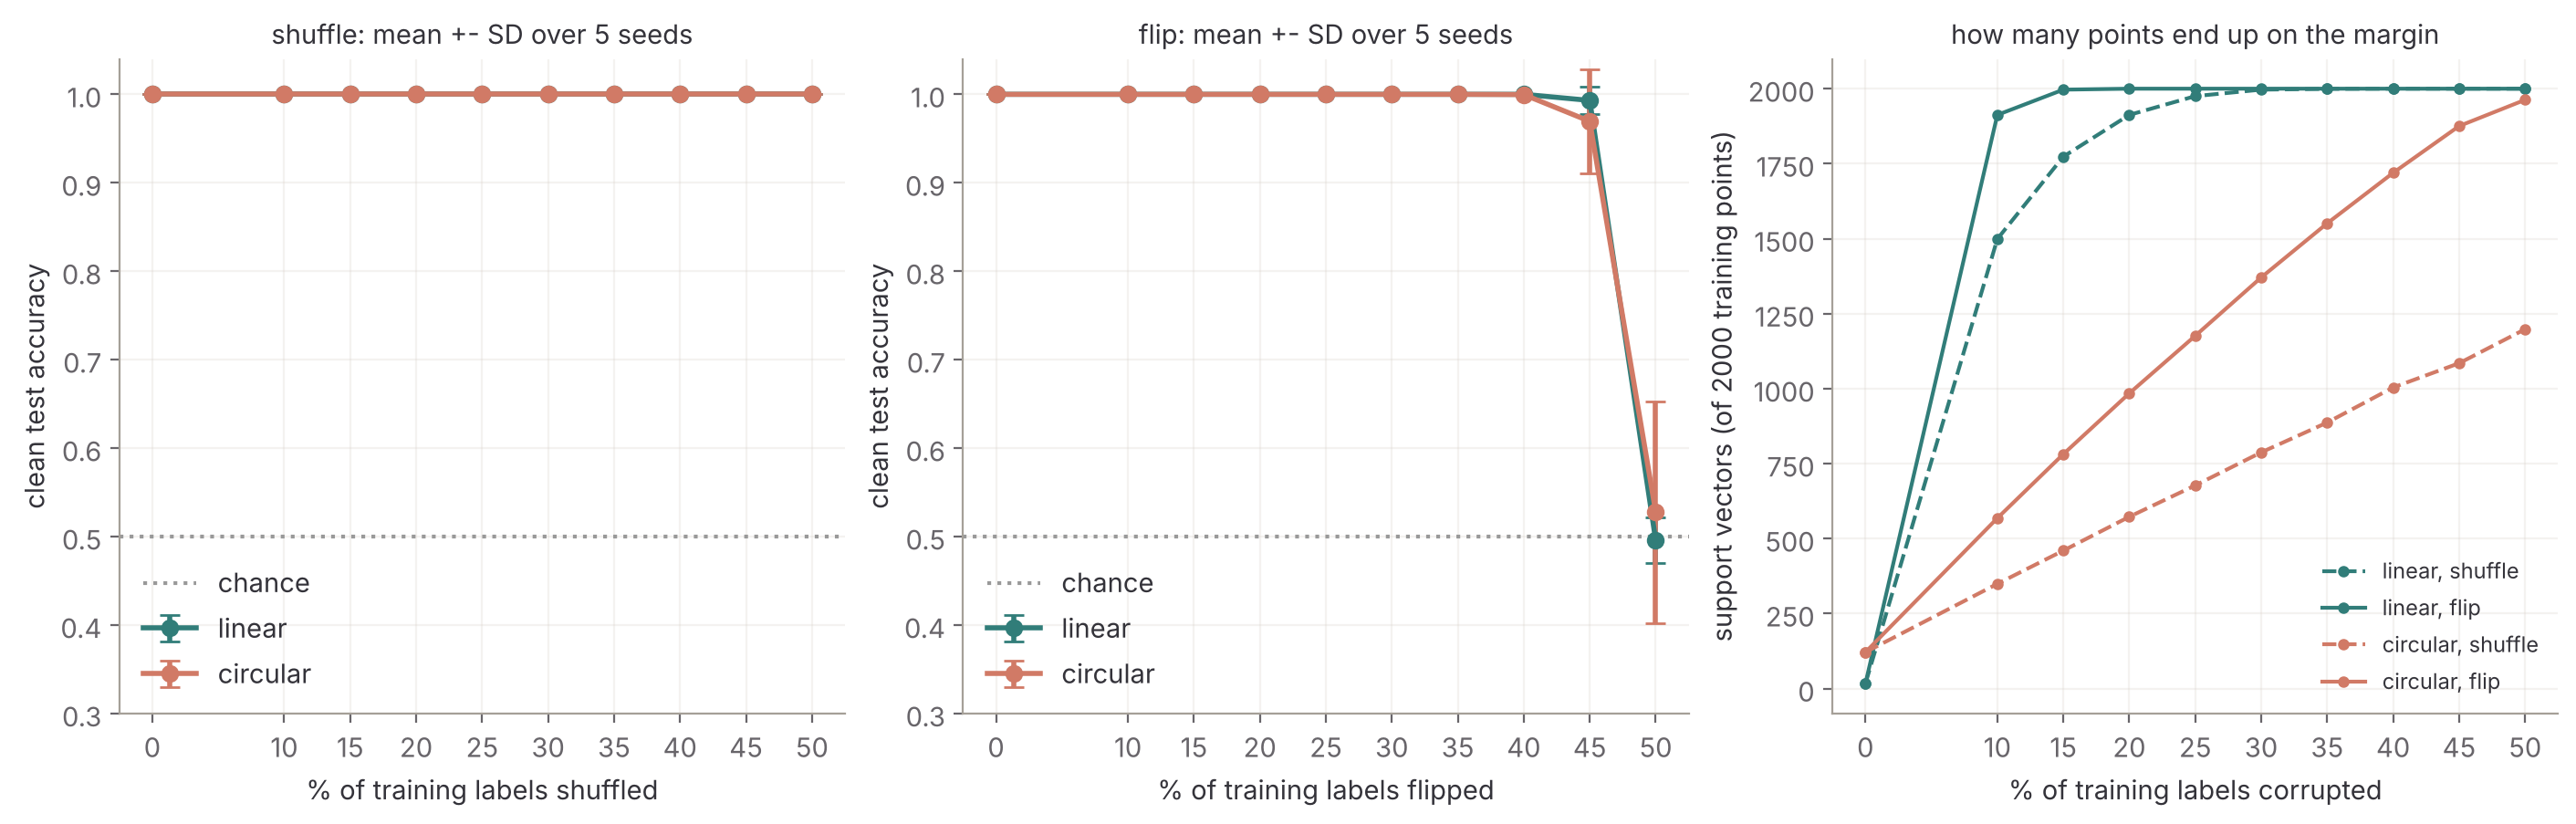

In [11]:
pcts = [0, 10, 15, 20, 25, 30, 35, 40, 45, 50]
seeds = [11, 22, 33, 44, 55]


def corrupt(y, pct, how, rng):
    y = y.copy()
    if pct == 0:
        return y
    ids = rng.choice(len(y), size=round(len(y) * pct / 100), replace=False)
    if how == 'shuffle':
        y[ids] = rng.permutation(y[ids])
    else:
        y[ids] = 1 - y[ids]
    return y


# linear svm has no support_ so we count points with y*f(x) <= 1 (inside the margin)
def count_sv(model, X, y):
    if hasattr(model[-1], 'support_'):
        return len(model[-1].support_)
    return int(np.sum((2 * y - 1) * model.decision_function(X) <= 1 + 1e-9))


q5 = []
for name, Xtr, ytr, Xte, yte in [('linear', XL_tr, yl_tr, XL_te, yl_te), ('circular', XC_tr, yc_tr, XC_te, yc_te)]:
    ids, _ = train_test_split(np.arange(len(ytr)), train_size=2000, stratify=ytr, random_state=SEED)
    xs, ys = Xtr[ids], ytr[ids]
    for how in ['shuffle', 'flip']:
        for pct in pcts:
            for s in seeds:
                y_bad = corrupt(ys, pct, how, np.random.default_rng(s))
                if name == 'linear':
                    m = lin_svm()
                else:
                    m = clone(best_svm)
                m.fit(xs, y_bad)
                q5.append({'dataset': name, 'method': how, 'pct': pct, 'seed': s,
                           'actually_wrong_pct': round(100 * float(np.mean(y_bad != ys)), 2),
                           'train_acc_vs_noisy': accuracy_score(y_bad, m.predict(xs)),
                           'test_acc': accuracy_score(yte, m.predict(Xte)), 'n_sv': count_sv(m, xs, y_bad)})
q5_df = pd.DataFrame(q5)
q5_sum = q5_df.groupby(['dataset', 'method', 'pct']).agg(wrong=('actually_wrong_pct', 'mean'), test_mean=('test_acc', 'mean'),
                                                         test_sd=('test_acc', 'std'), train_noisy=('train_acc_vs_noisy', 'mean'),
                                                         n_sv=('n_sv', 'mean')).round(4).reset_index()
print(q5_sum.to_string())
results['q5'] = q5_sum.to_dict('records')

fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), layout='constrained')
for ax, how in zip(axs[:2], ['shuffle', 'flip']):
    for name, color in zip(['linear', 'circular'], COLORS):
        d = q5_sum[(q5_sum.dataset == name) & (q5_sum.method == how)]
        ax.errorbar(d.pct, d.test_mean, yerr=d.test_sd, color=color, marker='o', linewidth=2, capsize=4, label=name)
    ax.axhline(.5, color='#999999', linestyle=':', label='chance')
    ax.set_ylim(0.3, 1.04)
    ax.set_xticks(pcts)
    ax.set_xlabel('% of training labels ' + ('shuffled' if how == 'shuffle' else 'flipped'))
    ax.set_ylabel('clean test accuracy')
    ax.set_title(f'{how}: mean +- SD over {len(seeds)} seeds', fontsize=10.5)
    ax.grid(alpha=.25)
    ax.legend(frameon=False, loc='lower left')
for name, color in zip(['linear', 'circular'], COLORS):
    for how, ls in [('shuffle', '--'), ('flip', '-')]:
        d = q5_sum[(q5_sum.dataset == name) & (q5_sum.method == how)]
        axs[2].plot(d.pct, d.n_sv, color=color, linestyle=ls, marker='o', markersize=3.5, label=f'{name}, {how}')
axs[2].set_xticks(pcts)
axs[2].set_xlabel('% of training labels corrupted')
axs[2].set_ylabel('support vectors (of 2000 training points)')
axs[2].set_title('how many points end up on the margin', fontsize=10.5)
axs[2].grid(alpha=.25)
axs[2].legend(frameon=False, fontsize=8.5)
save(fig, 'fig11_label_noise')

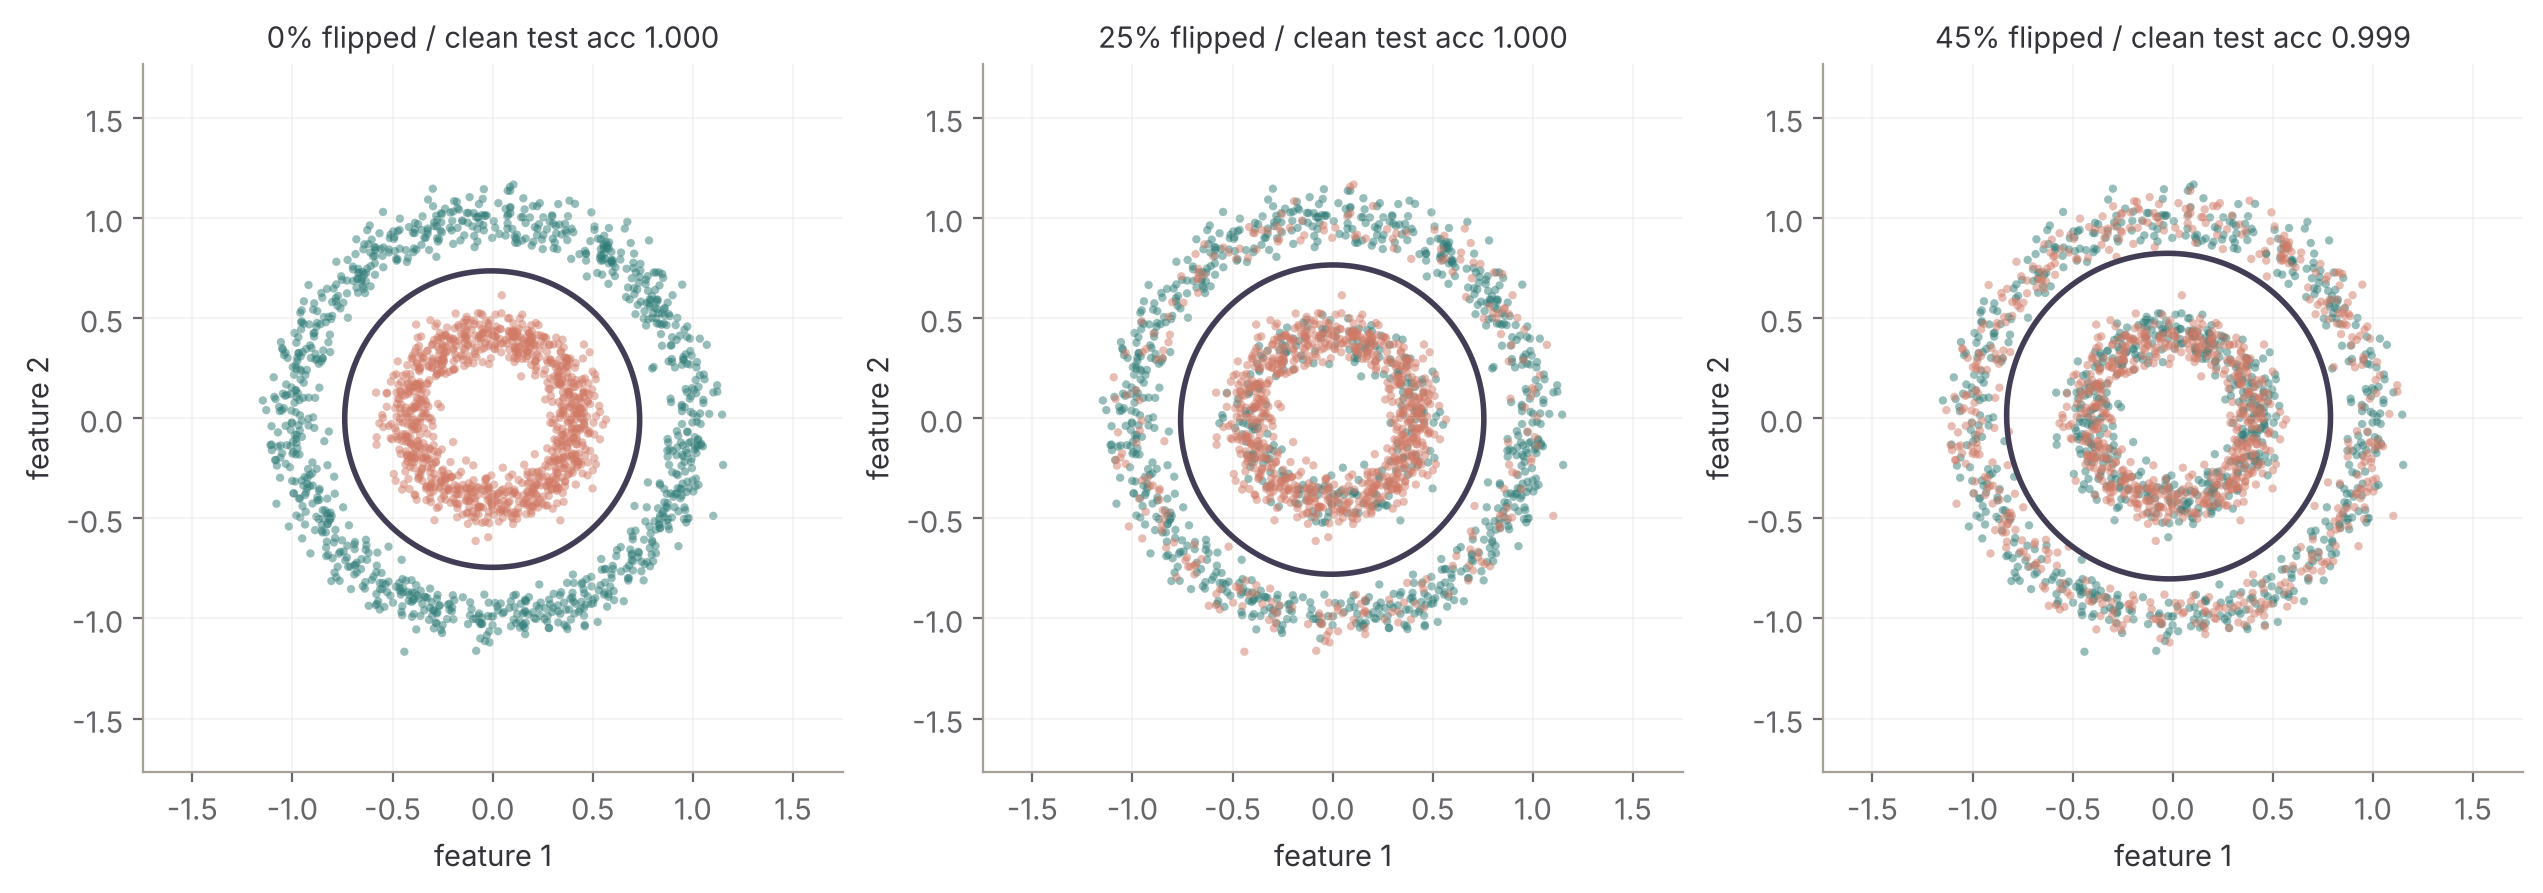

In [12]:
# how it looks with flipped labels
ids, _ = train_test_split(np.arange(len(yc_tr)), train_size=2000, stratify=yc_tr, random_state=SEED)
xs, ys = XC_tr[ids], yc_tr[ids]
fig, axs = plt.subplots(1, 3, figsize=(12.6, 4.3), layout='constrained')
for ax, pct in zip(axs, [0, 25, 45]):
    y_bad = corrupt(ys, pct, 'flip', np.random.default_rng(11))
    m = clone(best_svm).fit(xs, y_bad)
    plot_boundary(ax, m, xs, y_bad, f'{pct}% flipped / clean test acc {accuracy_score(yc_te, m.predict(XC_te)):.3f}')
save(fig, 'fig12_label_noise_examples')

## Q6 - higher dimensions
label noise (shuffle 0/15/25/50) for d = 2, 5, 10, 15. two versions:
A = new datasets in d dims (clusters / spheres), B = old 2d data + (d-2) random noise features

with 2000 train points almost everything was 100% so we use 500 here. gamma='scale' because gamma from 2d doesnt make sense in 15d

pct                                      0       15      25      50
version                dataset  dim                                
A: new d-dim data      circular 2    1.0000  1.0000  1.0000  1.0000
                                5    1.0000  1.0000  1.0000  0.9987
                                10   0.9975  0.9957  0.9945  0.9187
                                15   0.9960  0.9842  0.9792  0.8577
                       linear   2    1.0000  1.0000  1.0000  1.0000
                                5    1.0000  1.0000  1.0000  1.0000
                                10   1.0000  1.0000  0.9998  0.9987
                                15   1.0000  1.0000  1.0000  0.9973
B: 2D + noise features circular 2    1.0000  1.0000  1.0000  1.0000
                                5    1.0000  0.9997  0.9988  0.9755
                                10   0.8945  0.7980  0.7798  0.6935
                                15   0.6725  0.6312  0.6268  0.5872
                       linear   2    1.0000  1.0

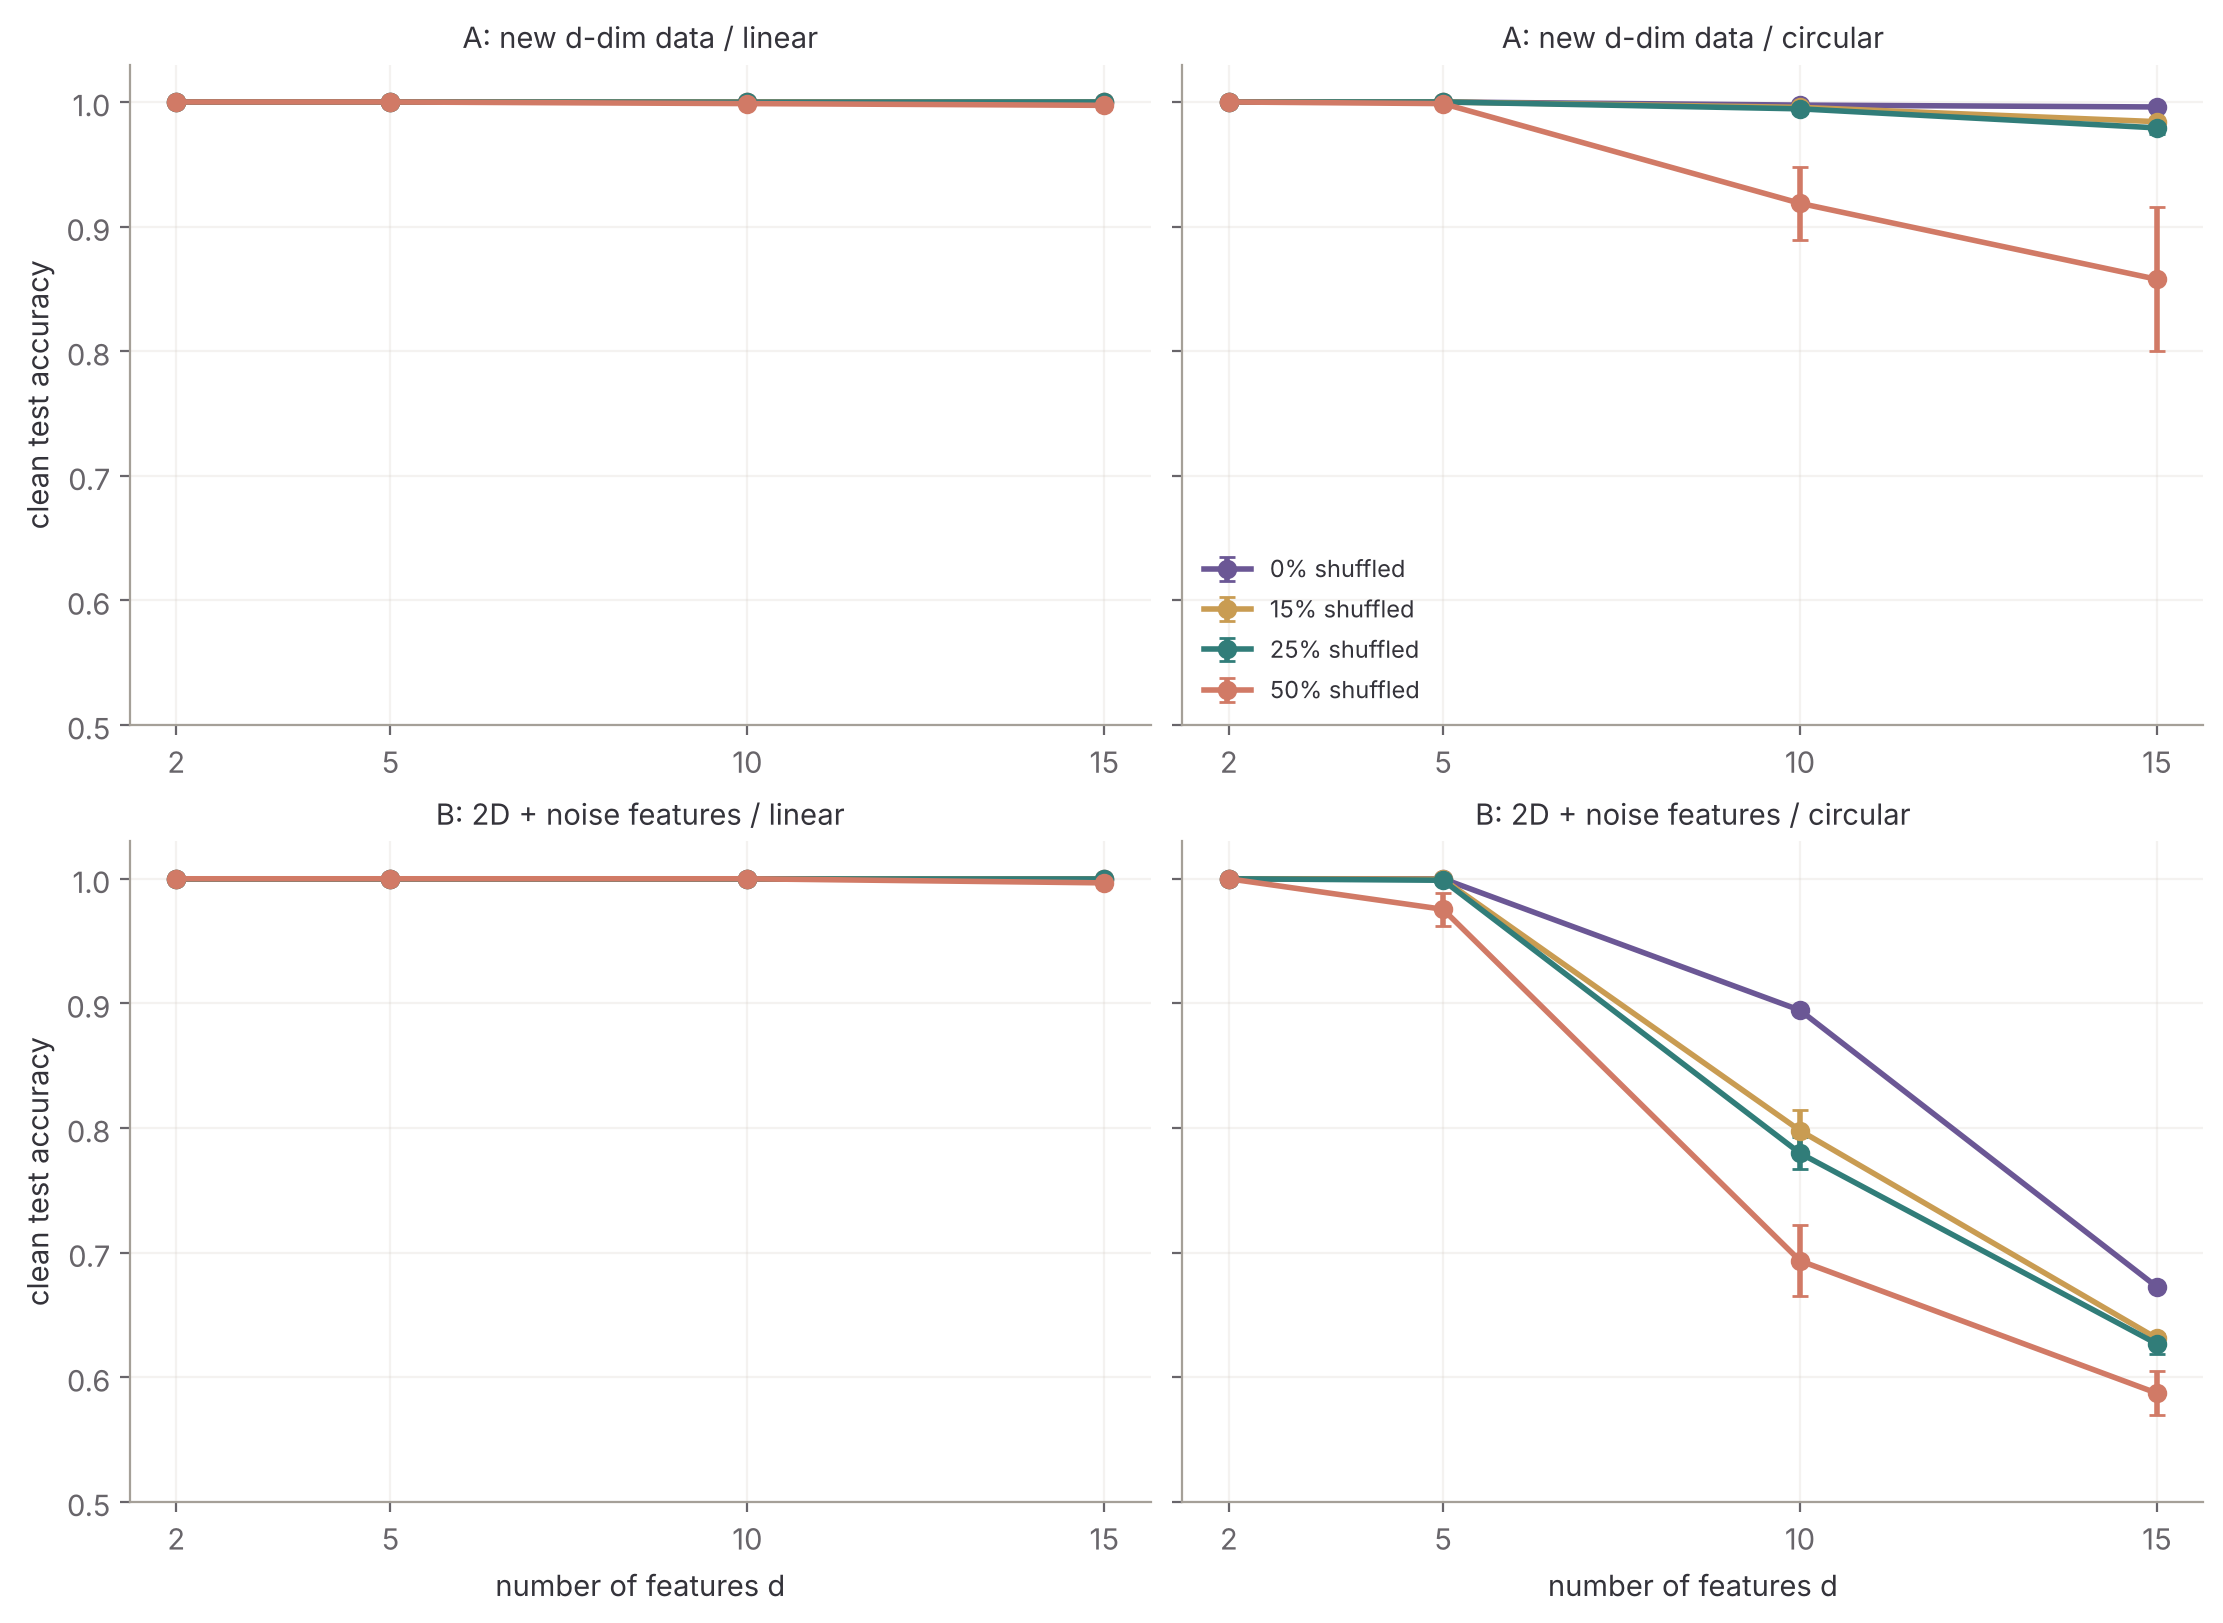

In [13]:
dims = [2, 5, 10, 15]
pcts6 = [0, 15, 25, 50]
seeds6 = [11, 22, 33]


def make_A(kind, d, seed, n=N):
    rng = np.random.default_rng(seed)
    y = np.repeat([0, 1], n // 2)
    if kind == 'linear':
        a = 3 * np.sqrt(2 / d)   # so the distance between centres is the same as in 2d
        X = np.where(y[:, None] == 0, -a, a) + rng.normal(0, .70, (n, d))
    else:
        u = rng.normal(size=(n, d))
        u = u / np.linalg.norm(u, axis=1, keepdims=True)   # random direction
        r = np.where(y == 0, 1.0, 0.42)                    # outer sphere = class 0 like make_circles
        X = u * r[:, None] + rng.normal(0, .065, (n, d))
    return X, y


def make_B(kind, d, seed):
    if kind == 'linear':
        X2, y = X_lin, y_lin
    else:
        X2, y = X_cir, y_cir
    noise = np.random.default_rng(1000 + d + seed).normal(0, 1, (len(y), d - 2))
    return np.column_stack([X2, noise]), y


q6 = []
for version, maker in [('A: new d-dim data', make_A), ('B: 2D + noise features', make_B)]:
    for kind in ['linear', 'circular']:
        for d in dims:
            X, y = maker(kind, d, SEED)
            Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
            ids, _ = train_test_split(np.arange(len(ytr)), train_size=500, stratify=ytr, random_state=SEED)
            for pct in pcts6:
                for s in seeds6:
                    y_bad = corrupt(ytr[ids], pct, 'shuffle', np.random.default_rng(s))
                    if kind == 'linear':
                        m = lin_svm()
                    else:
                        m = clone(best_svm).set_params(svc__gamma='scale')
                    m.fit(Xtr[ids], y_bad)
                    q6.append({'version': version, 'dataset': kind, 'dim': d, 'pct': pct, 'seed': s,
                               'test_acc': accuracy_score(yte, m.predict(Xte))})
q6_sum = pd.DataFrame(q6).groupby(['version', 'dataset', 'dim', 'pct']).test_acc.agg(['mean', 'std']).round(4).reset_index()
print(q6_sum.pivot_table(index=['version', 'dataset', 'dim'], columns='pct', values='mean'))
results['q6'] = q6_sum.to_dict('records')

fig, axs = plt.subplots(2, 2, figsize=(11, 8), layout='constrained', sharey=True)
for i, version in enumerate(['A: new d-dim data', 'B: 2D + noise features']):
    for j, kind in enumerate(['linear', 'circular']):
        for pct, color in zip(pcts6, EXTRA):
            d = q6_sum[(q6_sum.version == version) & (q6_sum.dataset == kind) & (q6_sum.pct == pct)]
            axs[i, j].errorbar(d.dim, d['mean'], yerr=d['std'], color=color, marker='o', linewidth=2, capsize=3,
                               label=f'{pct}% shuffled')
        axs[i, j].set_xticks(dims)
        axs[i, j].set_ylim(.5, 1.03)
        axs[i, j].set_title(f'{version} / {kind}', fontsize=10.5)
        axs[i, j].grid(alpha=.25)
axs[1, 0].set_xlabel('number of features d')
axs[1, 1].set_xlabel('number of features d')
axs[0, 0].set_ylabel('clean test accuracy')
axs[1, 0].set_ylabel('clean test accuracy')
axs[0, 1].legend(frameon=False, fontsize=8.5, loc='lower left')
save(fig, 'fig13_dimensions')

kernel    poly             rbf        
pct         0       50      0       50
dim                                   
2       1.0000  1.0000  1.0000  1.0000
5       1.0000  0.9755  0.9535  0.9007
10      0.8945  0.6935  0.7610  0.6788
15      0.6725  0.5872  0.6715  0.6148


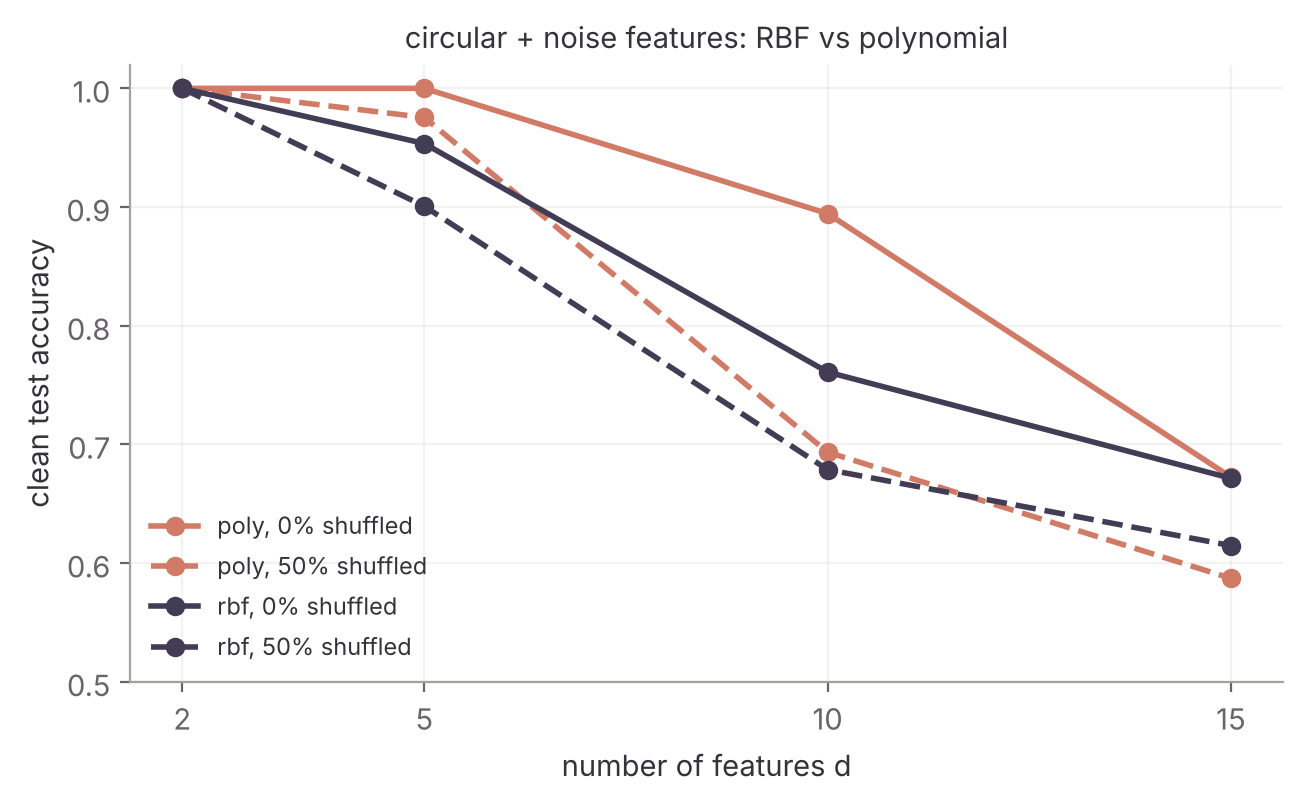

In [14]:
# version B circular drops a lot. is it because of poly? try rbf too
kd = []
for d in dims:
    X, y = make_B('circular', d, SEED)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
    ids, _ = train_test_split(np.arange(len(ytr)), train_size=500, stratify=ytr, random_state=SEED)
    for kernel in ['rbf', 'poly']:
        for pct in [0, 50]:
            for s in seeds6:
                y_bad = corrupt(ytr[ids], pct, 'shuffle', np.random.default_rng(s))
                m = clone(kernel_models[kernel]).set_params(svc__gamma='scale').fit(Xtr[ids], y_bad)
                kd.append({'dim': d, 'kernel': kernel, 'pct': pct, 'seed': s, 'test_acc': accuracy_score(yte, m.predict(Xte))})
kd = pd.DataFrame(kd).groupby(['kernel', 'pct', 'dim']).test_acc.mean().round(4).reset_index()
print(kd.pivot_table(index='dim', columns=['kernel', 'pct'], values='test_acc'))
results['q6_kernels'] = kd.to_dict('records')

fig, ax = plt.subplots(figsize=(6.4, 3.9), layout='constrained')
for (kernel, pct), d in kd.groupby(['kernel', 'pct']):
    ax.plot(d.dim, d.test_acc, marker='o', linewidth=2, color=INK if kernel == 'rbf' else COLORS[1],
            linestyle='-' if pct == 0 else '--', label=f'{kernel}, {pct}% shuffled')
ax.set_xticks(dims)
ax.set_ylim(.5, 1.02)
ax.set_xlabel('number of features d')
ax.set_ylabel('clean test accuracy')
ax.set_title('circular + noise features: RBF vs polynomial', fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5, loc='lower left')
ax.grid(alpha=.25)
save(fig, 'fig14_kernels_vs_dim')

## Bonus - 70% threshold
we were not sure what exactly is meant so we did 2 things:
(a) models from q4 (20 per augmentation) + more and more noise on the TEST inputs -> where acc < 70%
(b) more and more noise in the TRAINING augmentation -> where clean test acc < 70%

clean rings none {'crossing_of_mean_curve': 0.4497602739726026, 'crossing_per_model_mean': 0.44973817150669254, 'crossing_per_model_sd': 0.0013355614518835229, 'acc_at_sd0': 1.0}


clean rings low {'crossing_of_mean_curve': 0.4505877413937866, 'crossing_per_model_mean': 0.45058907134111525, 'crossing_per_model_sd': 0.0017484818732346743, 'acc_at_sd0': 1.0}


clean rings high {'crossing_of_mean_curve': 0.4697948494107378, 'crossing_per_model_mean': 0.46983284428138317, 'crossing_per_model_sd': 0.003613968952433787, 'acc_at_sd0': 0.9952249999999999}


hard rings none {'crossing_of_mean_curve': 0.25830917874396137, 'crossing_per_model_mean': 0.258340624210915, 'crossing_per_model_sd': 0.0029584229346418123, 'acc_at_sd0': 0.8393333333333333}


hard rings low {'crossing_of_mean_curve': 0.2592509363295879, 'crossing_per_model_mean': 0.259286722335681, 'crossing_per_model_sd': 0.0034505732336157532, 'acc_at_sd0': 0.8385999999999999}


hard rings high {'crossing_of_mean_curve': 0.22108280254777088, 'crossing_per_model_mean': 0.22172070053374196, 'crossing_per_model_sd': 0.010898647963545246, 'acc_at_sd0': 0.7773999999999999}


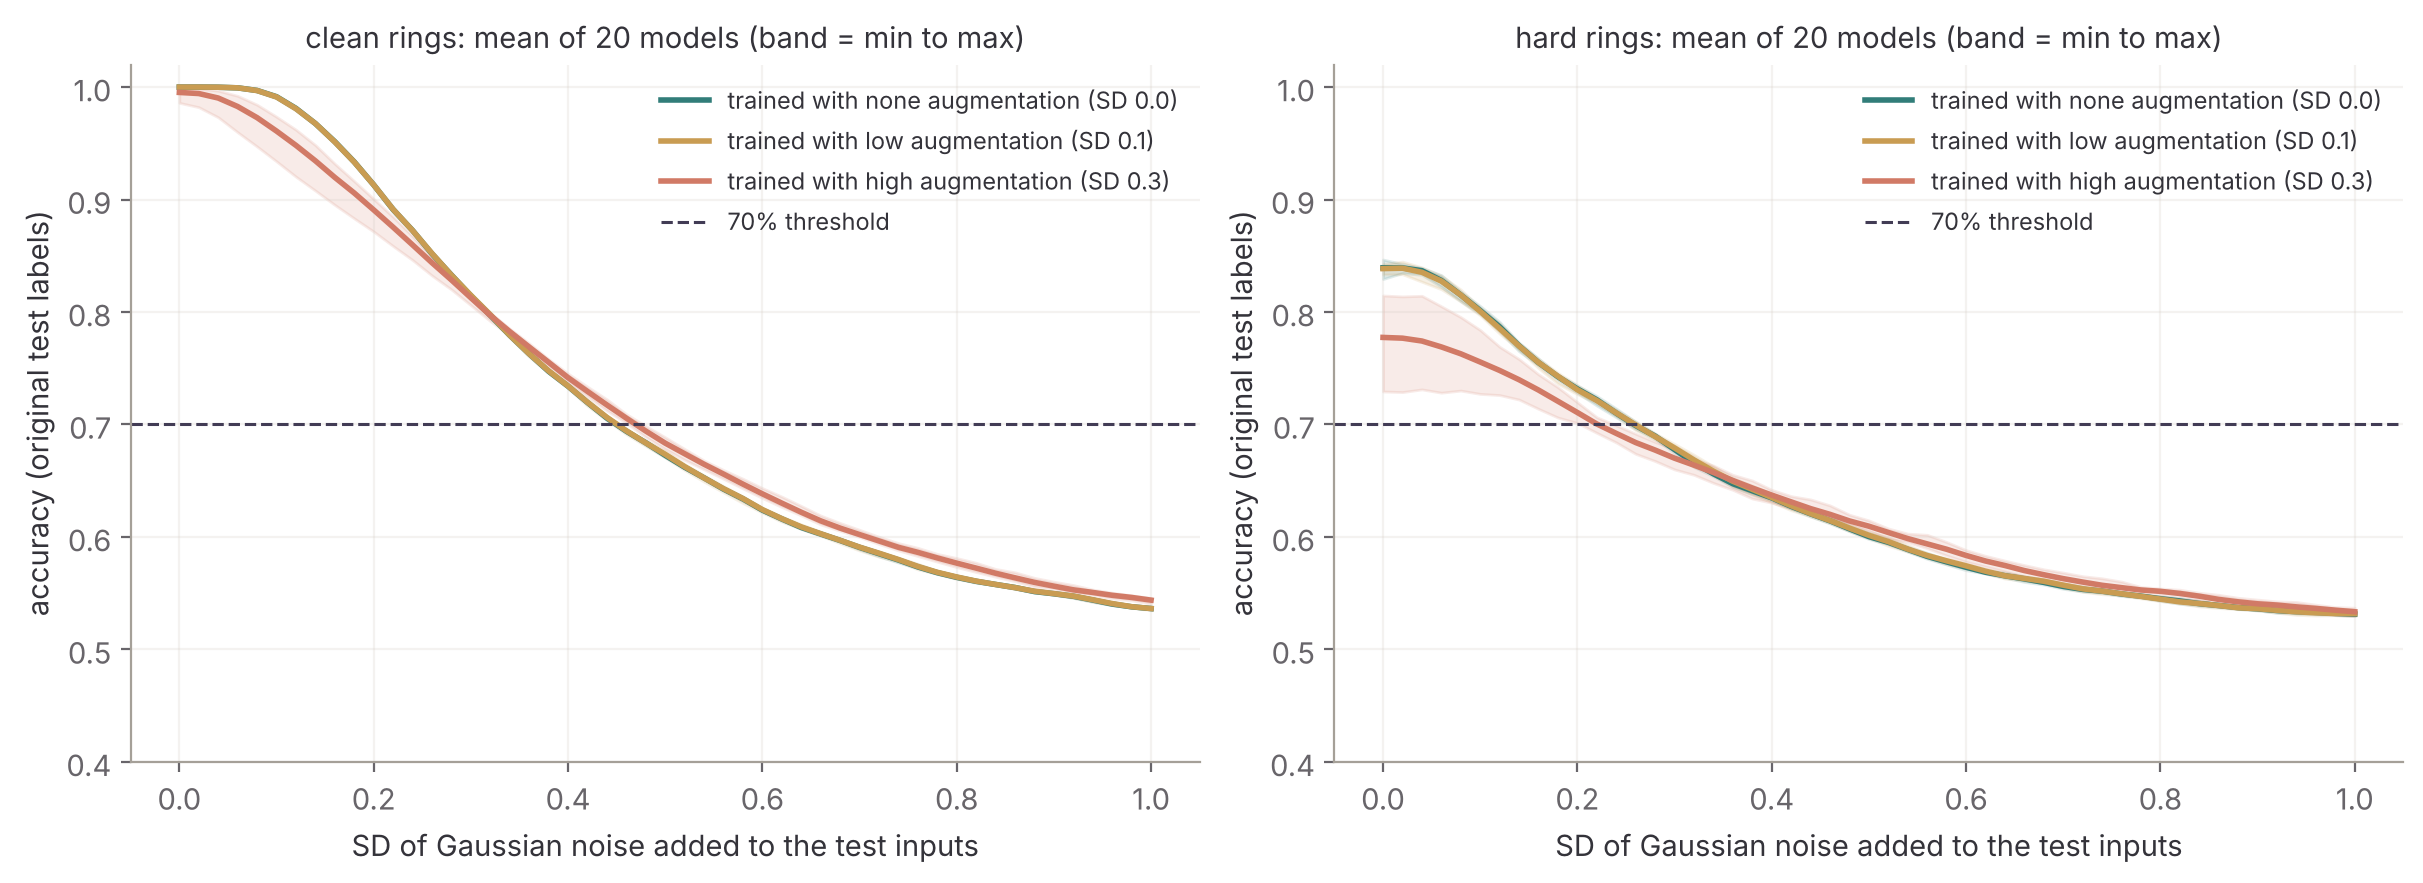

In [15]:
thr = .70
test_sds = np.round(np.arange(0, 1.01, .02), 2)


# first sd where acc goes below thr, linear interpolation between the two grid points
def crossing(sds, acc):
    below = np.where(acc < thr)[0]
    if len(below) == 0:
        return None
    i = below[0]
    if i == 0:
        return float(sds[0])
    return float(sds[i - 1] + (acc[i - 1] - thr) * (sds[i] - sds[i - 1]) / (acc[i - 1] - acc[i]))


bonus_a = {}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), layout='constrained')
for ax, (dname, (base_model, Xp, yp, Xt, yt)) in zip(axs, setups.items()):
    for ci, (cond, sd_aug) in enumerate(noise_sd.items()):
        curves = []
        for s in range(20):
            rng = np.random.default_rng(777 + 100 * ci + s)
            ids = rng.choice(len(yp), 1000, replace=False)
            m = clone(base_model).fit(Xp[ids] + rng.normal(0, sd_aug, (1000, 2)), yp[ids])
            curve = []
            for sd in test_sds:
                accs = []
                for k in range(5):  # 5 noise draws per sd
                    accs.append(accuracy_score(yt, m.predict(Xt + np.random.default_rng(500 + k).normal(0, sd, Xt.shape))))
                curve.append(np.mean(accs))
            curves.append(curve)
        curves = np.array(curves)
        mean = curves.mean(0)
        per_model = [crossing(test_sds, c) for c in curves]
        per_model = [p for p in per_model if p is not None]
        bonus_a[dname + ' / ' + cond] = {'crossing_of_mean_curve': crossing(test_sds, mean),
                                         'crossing_per_model_mean': float(np.mean(per_model)),
                                         'crossing_per_model_sd': float(np.std(per_model)), 'acc_at_sd0': float(mean[0])}
        print(dname, cond, bonus_a[dname + ' / ' + cond])
        ax.plot(test_sds, mean, color=COND_COLORS[cond], linewidth=2, label=f'trained with {cond} augmentation (SD {sd_aug})')
        ax.fill_between(test_sds, curves.min(0), curves.max(0), color=COND_COLORS[cond], alpha=.15)
    ax.axhline(thr, color=INK, linestyle='--', linewidth=1.1, label='70% threshold')
    ax.set_xlabel('SD of Gaussian noise added to the test inputs')
    ax.set_ylabel('accuracy (original test labels)')
    ax.set_title(f'{dname}: mean of 20 models (band = min to max)', fontsize=10.5)
    ax.set_ylim(.4, 1.02)
    ax.grid(alpha=.25)
    ax.legend(frameon=False, fontsize=8.5)
save(fig, 'fig15_bonus_test_noise')
results['bonus_a'] = bonus_a

clean rings crosses 70% at aug sd = 0.47758866512208165


hard rings crosses 70% at aug sd = 0.37878787878787884


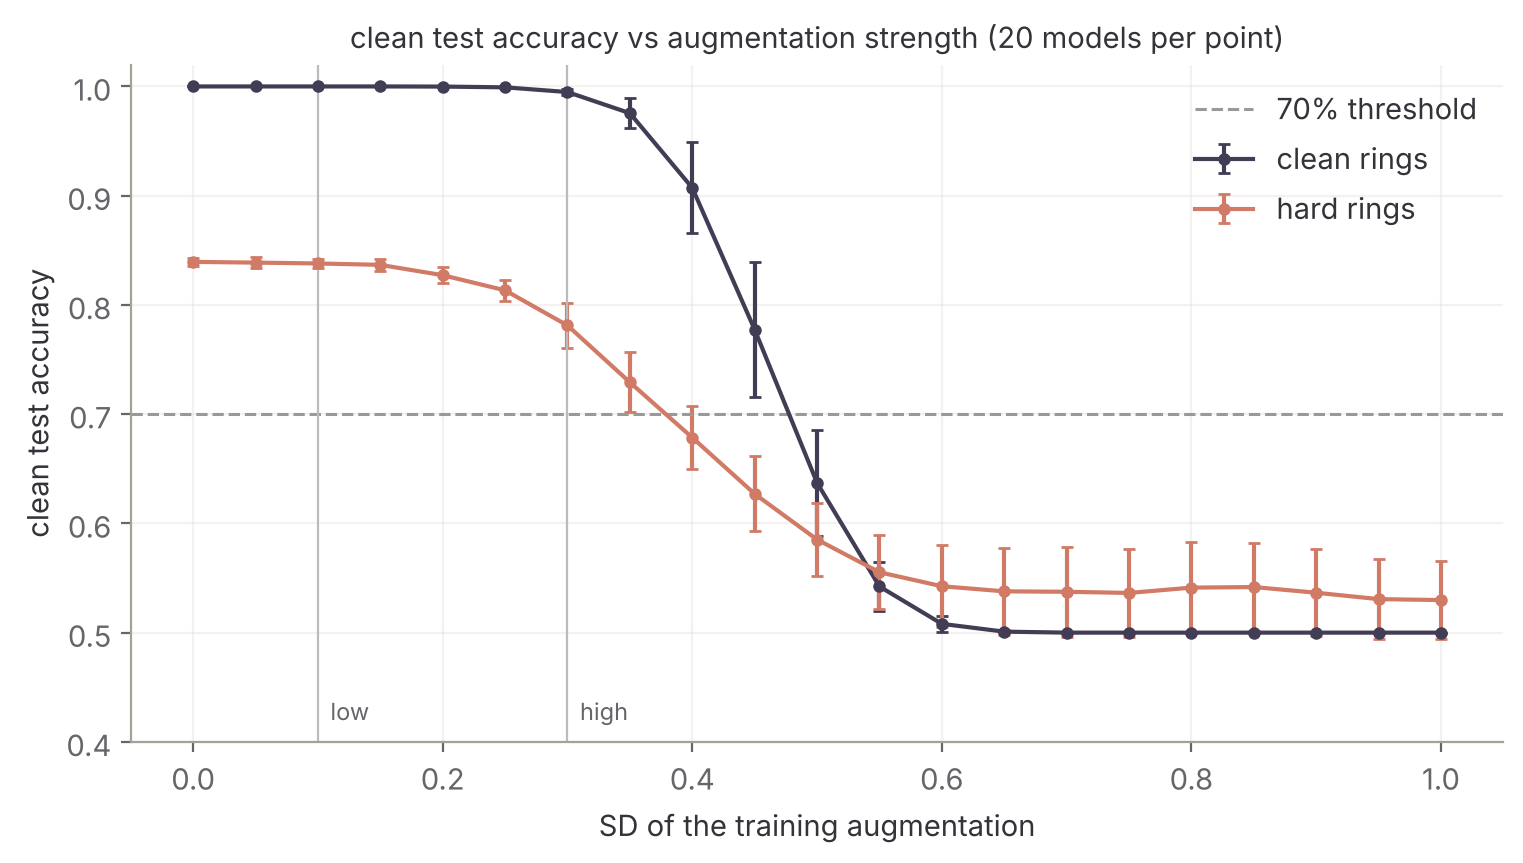

In [16]:
train_sds = np.round(np.arange(0, 1.01, .05), 2)
bonus_b = {}
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout='constrained')
for (dname, (base_model, Xp, yp, Xt, yt)), color in zip(setups.items(), [INK, COLORS[1]]):
    all_acc = []
    for sd in train_sds:
        accs = []
        for s in range(20):
            rng = np.random.default_rng(900 + s)
            ids = rng.choice(len(yp), 1000, replace=False)
            m = clone(base_model).fit(Xp[ids] + rng.normal(0, sd, (1000, 2)), yp[ids])
            accs.append(accuracy_score(yt, m.predict(Xt)))
        all_acc.append(accs)
    all_acc = np.array(all_acc)
    bonus_b[dname] = {'crossing_sd': crossing(train_sds, all_acc.mean(1)), 'curve_mean': all_acc.mean(1).round(4).tolist()}
    print(dname, 'crosses 70% at aug sd =', bonus_b[dname]['crossing_sd'])
    ax.errorbar(train_sds, all_acc.mean(1), yerr=all_acc.std(1), color=color, marker='o', markersize=3.5, capsize=2, label=dname)
ax.axhline(thr, color='#999999', linestyle='--', linewidth=1.1, label='70% threshold')
ax.axvline(.1, color='#BBBBBB', linewidth=.8)
ax.text(.11, .42, 'low', fontsize=8.5, color='#68656A')
ax.axvline(.3, color='#BBBBBB', linewidth=.8)
ax.text(.31, .42, 'high', fontsize=8.5, color='#68656A')
ax.set_xlabel('SD of the training augmentation')
ax.set_ylabel('clean test accuracy')
ax.set_title('clean test accuracy vs augmentation strength (20 models per point)', fontsize=10.5)
ax.set_ylim(.4, 1.02)
ax.grid(alpha=.25)
ax.legend(frameon=False)
save(fig, 'fig16_bonus_train_noise')
results['bonus_b'] = bonus_b

In [17]:
# save numbers
def fix(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)

with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=fix)
print('done')

done
